# 02. O fluxo da política do MCMV-FAR contado pelos dados (v2, fontes auditadas)

Este notebook segue o mapa da política do FAR (`mapeamento-fluxos/novos_mapeamentos_politica/subsidiada/Programa MCMV - Subsidiada - FAR.pdf`) etapa por etapa e, em cada uma, mostra o que os dados do Gov Hub já respondem: quanto dinheiro existe, como as obras estão no Brasil, quais portarias regem a carteira e o que chegou às famílias.

O fluxo da política, na ordem do mapa:

1. **Orçamento da União**: LOA (ação 00AF, integralização de cotas ao FAR), empenho e pagamento, que formam o saldo do FAR na CAIXA (GFAR).
2. **Seleção**: avaliação orçamentária, portaria de abertura do ciclo, apresentação de propostas, análise preliminar, portaria de enquadramento, documentação de viabilidade e portaria de aptidão à contratação.
3. **Contratação**: contrato entre agente financeiro, construtora e ente público (em até 120 dias), com contrapartidas obrigatórias.
4. **Execução**: execução e medição da obra, vistoria e atestado de avanço.
5. **Desembolso**: por medição, direto ao credor, com o ciclo repetido a cada medição.
6. **Entrega**: conclusão e habite-se, designação da UH, contrato com as famílias e entrega das chaves.
7. **Pós-ocupação** e trabalho social (da indicação das famílias ao pós-ocupação).

As perguntas que orientam a leitura vêm da oficina (grupo do FAR: panorama das contratações, andamento das obras com atrasos e paralisações, contrapartidas, natureza do empreendimento, perfil das famílias) e das diretrizes do secretário (falar a língua da CAIXA, ler físico e financeiro juntos, curva S por mês de obra). As recomendações do professor Mintsu entram no fim, na leitura da curva S por mês de obra.

**Fonte:** Postgres medalhão do Lab (`10.0.0.50/cidades`), modelos dbt `far_dbt`. Universo: Novo MCMV-FAR (contratações desde fevereiro de 2024). Data de posição: agosto de 2026.

<div style="border:2px solid #d03b3b;background:#fff4f4;padding:10px 14px;border-radius:6px;margin:6px 0"><b style="color:#d03b3b">⚠ Fora do banco: resumo da auditoria deste notebook (30/10/2026)</b><ul style="margin:6px 0 0 0"><li>Tudo que é carteira, obra, financeiro, propostas, GEHIS e famílias vem do Postgres do Lab (10.0.0.50), schemas prata e ouro, mais a bronze do GEHIS (não há prata do GEHIS para o FAR).</li><li>Não vêm do banco: a linha do tempo do orçamento fora de 2025 (arquivos de pesquisa), a identificação do exercício da extração SIAFI (dedução), os dicionários do GFAR (MNPO 2023), a descrição das portarias (pesquisa), a portaria atribuída aos 84 APFs sem informação (imputação), a data de hoje e as regras de régua, faixa e motivo (parâmetros do notebook), e as interpretações vindas das reuniões (secretário, Mintsu). Cada uma está marcada em vermelho no ponto em que entra.</li><li>Caminho geral para levar ao banco: seeds no dbt (dicionários e valores de documento), colunas novas na prata (exercício do SIAFI, portaria imputada), modelos ouro com os parâmetros da régua, e descrições no OpenMetadata para as interpretações.</li></ul></div>

In [1]:
import sys; sys.path.insert(0, "../..")
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from src import db

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 60); pd.set_option("display.max_rows", 200)
INTERIM = Path("../../data/interim"); INTERIM.mkdir(parents=True, exist_ok=True)

# Paleta (dataviz: categórica em ordem fixa, status reservado, sequencial em um só matiz)
C = {"azul": "#2a78d6", "laranja": "#eb6834", "verde": "#1baf7a", "amarelo": "#eda100", "roxo": "#4a3aa7", "cinza": "#9a9892"}
STATUS = {"bom": "#0ca30c", "atencao": "#fab219", "serio": "#ec835a", "critico": "#d03b3b", "neutro": "#9a9892"}
SEQ = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#2a78d6", "#1c5cab", "#104281"]
plt.rcParams.update({
    "figure.dpi": 110, "figure.figsize": (10, 4.2), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e2", "grid.linewidth": 0.6, "axes.edgecolor": "#c9c8c4",
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left", "font.size": 10,
    "legend.frameon": False, "axes.axisbelow": True,
})

def brl(x, casas=2):
    """R$ em bi/mi/mil, formato pt-BR."""
    if x is None or (isinstance(x, float) and np.isnan(x)): return "–"
    for div, suf in [(1e9, " bi"), (1e6, " mi"), (1e3, " mil")]:
        if abs(x) >= div:
            return ("R$ " + f"{x/div:,.{casas}f}" + suf).replace(",", "X").replace(".", ",").replace("X", ".")
    return ("R$ " + f"{x:,.0f}").replace(",", "X").replace(".", ",").replace("X", ".")

def num(x):
    return f"{x:,.0f}".replace(",", ".")

def rotular_barras(ax, fmt=num, dx=0, fontsize=9, horizontal=False):
    for p in ax.patches:
        v = p.get_width() if horizontal else p.get_height()
        if v == 0 or np.isnan(v): continue
        if horizontal:
            ax.annotate(fmt(v), (v, p.get_y() + p.get_height()/2), xytext=(4, 0), textcoords="offset points", va="center", fontsize=fontsize, color="#52514e")
        else:
            ax.annotate(fmt(v), (p.get_x() + p.get_width()/2, v), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=fontsize, color="#52514e")

def cache(nome, sql):
    f = INTERIM / f"{nome}.parquet"
    if f.exists():
        return pd.read_parquet(f)
    df = db.ler_sql(sql); df.to_parquet(f); return df

FONTES = Path("../../fontes")
OUT = Path("../../output"); OUT.mkdir(exist_ok=True)
STATUS_C = STATUS
ficha_contratado_total = db.ler_sql("select sum(valor_contratado) from ouro.ouro_far_ficha_empreendimento").iloc[0, 0]
print("conectado em", db.HOST)

conectado em 10.0.0.50


## 1. Orçamento da União: a ação 00AF ao longo do tempo

O FAR não recebe transferências diretas por empreendimento. A União integraliza cotas no fundo pela ação orçamentária **00AF (Integralização de cotas ao Fundo de Arrendamento Residencial)**, e a CAIXA, como gestora (GFAR), usa o saldo do fundo para contratar e pagar as obras. A tabela tipada `prata.prata_conjuntura_siafi_dotacao_execucao` traz a extração do Tesouro Gerencial; a soma da dotação inicial das suas linhas da 00AF (R$ 2,53 bi + R$ 6,72 bi = R$ 9,245 bi) é exatamente a dotação da LOA 2025, o que identifica a extração como o exercício de 2025. Para montar a linha do tempo, junto a ela a execução de 2024 publicada nos dados abertos do MCid e as LOAs de 2025 e 2026 (Volume IV), que estão em `mapeamento-fluxos/fontes_pesquisa_2026-08-31/`.

In [2]:
siafi = cache("siafi_prata_subsidiado", """
select acao_governo_codigo as acao, acao_governo_nome as nome, plano_orcamentario_medida as po, ug_executora_codigo as ug, ug_executora_nome as ug_nome,
       elemento_despesa_codigo as nd, fixacao_despesa_loa, dotacao_inicial, dotacao_atualizada, despesas_empenhadas, despesas_pagas, restos_a_pagar_inscritos, restos_a_pagar_pagos
from prata.prata_conjuntura_siafi_dotacao_execucao
where acao_governo_codigo in ('00AF','00CY','00CX','00TI')""")
LINHA = {"00AF": "FAR", "00CY": "FDS / Entidades", "00CX": "Rural", "00TI": "FNHIS Sub 50"}
siafi["linha"] = siafi.acao.map(LINHA)
display(siafi[siafi.acao == "00AF"][["ug","ug_nome","nd","fixacao_despesa_loa","dotacao_inicial","dotacao_atualizada","despesas_empenhadas","despesas_pagas","restos_a_pagar_pagos"]].style.format(brl, subset=["fixacao_despesa_loa","dotacao_inicial","dotacao_atualizada","despesas_empenhadas","despesas_pagas","restos_a_pagar_pagos"]))
ag = siafi.groupby("linha")[["dotacao_inicial","dotacao_atualizada","despesas_empenhadas","despesas_pagas","restos_a_pagar_pagos"]].sum().reindex(["FAR","FDS / Entidades","Rural","FNHIS Sub 50"])
display(ag.style.format(brl))
far25 = ag.loc["FAR"]

,ug,ug_nome,nd,fixacao_despesa_loa,dotacao_inicial,dotacao_atualizada,despesas_empenhadas,despesas_pagas,restos_a_pagar_pagos
1,560004,SUBSECRETARIA DE PLANEJ.ORCAM.E ADM-SPOA/MCID,0,"R$ 10,70 bi","R$ 2,53 bi","R$ 84,90 mi",R$ 0,R$ 0,R$ 0
2,560004,SUBSECRETARIA DE PLANEJ.ORCAM.E ADM-SPOA/MCID,84,R$ 0,"R$ 6,72 bi","R$ 6,72 bi",R$ 0,R$ 0,R$ 0
3,560005,SECRETARIA NACIONAL DE HABITACAO,84,R$ 0,R$ 0,R$ 0,"R$ 6,72 bi","R$ 6,72 bi","R$ 667,79 mi"


,dotacao_inicial,dotacao_atualizada,despesas_empenhadas,despesas_pagas,restos_a_pagar_pagos
linha,,,,,
FAR,"R$ 9,25 bi","R$ 6,80 bi","R$ 6,72 bi","R$ 6,72 bi","R$ 667,79 mi"
FDS / Entidades,"R$ 902,59 mi","R$ 244,49 mi","R$ 171,59 mi","R$ 171,59 mi",R$ 0
Rural,"R$ 735,76 mi","R$ 735,76 mi","R$ 735,76 mi","R$ 735,76 mi",R$ 0
FNHIS Sub 50,R$ 0,R$ 0,"R$ 136,81 mi",R$ 0,"R$ 970,19 mil"


<div style="border:2px solid #d03b3b;background:#fff4f4;padding:10px 14px;border-radius:6px;margin:6px 0"><b style="color:#d03b3b">⚠ Fora do banco: o exercício da extração SIAFI é uma dedução</b><ul style="margin:6px 0 0 0"><li>A tabela <code>prata.prata_conjuntura_siafi_dotacao_execucao</code> não tem coluna de ano. Identifiquei o exercício 2025 porque a soma da dotação inicial da 00AF (R$ 2,53 bi + R$ 6,72 bi = R$ 9,245 bi) é exatamente a dotação da LOA 2025.</li><li><b>Como levar ao banco:</b> incluir a coluna <code>exercicio</code> na bronze e na prata do SIAFI, lida dos parâmetros da extração do Tesouro Gerencial (ou do nome do arquivo, que hoje é <code>dotacao_execucao_outras_fontes_mcid.csv</code>, sem data).</li></ul></div>

,dotacao_inicial,dotacao_atualizada,empenhado,pago,uh_meta_loa,fonte
ano,,,,,,
2024,–,"R$ 8,47 bi","R$ 8,47 bi","R$ 7,80 bi",–,"Execução orçamentária SNH 2024 (dados abertos MCid, posição 30/12/2024)"
2025,"R$ 9,25 bi","R$ 6,80 bi","R$ 6,72 bi","R$ 6,72 bi",56.375,"SIAFI / Tesouro Gerencial na prata (extração de ago/2026, exercício 2025); meta de UH da LOA 2025 vol. IV"
2026,"R$ 5,81 bi",–,–,–,28.109,LOA 2026 vol. IV (Lei 15.346/2026); execução ainda não extraída


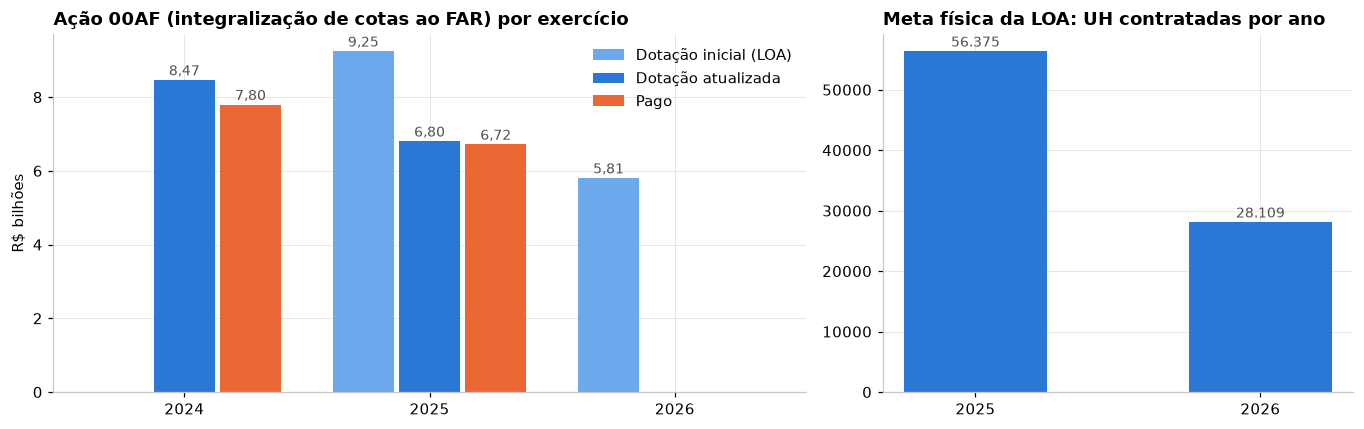

2024: dotação R$ 8,47 bi, pago R$ 7,80 bi | 2025: LOA R$ 9,25 bi, atualizada R$ 6,80 bi, pago R$ 6,72 bi | 2026: LOA R$ 5,81 bi
Pago acumulado 2024 + 2025: R$ 14,52 bi contra R$ 24,96 bi contratados na carteira (etapa 3)


In [3]:
# Linha do tempo da 00AF: 2024 (execução publicada pelo MCid), 2025 (SIAFI na prata), 2026 (LOA)
import csv
exec24 = pd.read_csv(FONTES / "exec_snh_2024.csv", sep=";", encoding="utf-8-sig", decimal=",", thousands=".").drop_duplicates()
e24 = exec24[exec24["Ação Orçamentária"] == "00AF"].iloc[0]
tl = pd.DataFrame([
    {"ano": 2024, "dotacao_inicial": np.nan, "dotacao_atualizada": e24["Dotação"], "empenhado": e24["Empenho"], "pago": e24["Pagamento"], "uh_meta_loa": np.nan,
     "fonte": "Execução orçamentária SNH 2024 (dados abertos MCid, posição 30/12/2024)"},
    {"ano": 2025, "dotacao_inicial": far25.dotacao_inicial, "dotacao_atualizada": far25.dotacao_atualizada, "empenhado": far25.despesas_empenhadas, "pago": far25.despesas_pagas, "uh_meta_loa": 56375,
     "fonte": "SIAFI / Tesouro Gerencial na prata (extração de ago/2026, exercício 2025); meta de UH da LOA 2025 vol. IV"},
    {"ano": 2026, "dotacao_inicial": 5_807_138_041, "dotacao_atualizada": np.nan, "empenhado": np.nan, "pago": np.nan, "uh_meta_loa": 28109,
     "fonte": "LOA 2026 vol. IV (Lei 15.346/2026); execução ainda não extraída"},
]).set_index("ano")
display(tl.style.format({c: brl for c in ["dotacao_inicial","dotacao_atualizada","empenhado","pago"]} | {"uh_meta_loa": num}, na_rep="–"))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4), gridspec_kw={"width_ratios": [1.6, 1]})
x = np.arange(len(tl)); w = 0.27
for i, (col, rot, cor) in enumerate([("dotacao_inicial","Dotação inicial (LOA)",SEQ[2]),("dotacao_atualizada","Dotação atualizada",C["azul"]),("pago","Pago",C["laranja"])]):
    axes[0].bar(x + (i-1)*w, tl[col].fillna(0)/1e9, w*0.92, label=rot, color=cor)
axes[0].set_xticks(x); axes[0].set_xticklabels(tl.index); axes[0].set_ylabel("R$ bilhões"); axes[0].legend(loc="upper right")
axes[0].set_title("Ação 00AF (integralização de cotas ao FAR) por exercício")
rotular_barras(axes[0], fmt=lambda v: f"{v:.2f}".replace(".", ","))
axes[1].bar(["2025", "2026"], tl.loc[[2025, 2026], "uh_meta_loa"], color=C["azul"], width=0.5)
axes[1].set_title("Meta física da LOA: UH contratadas por ano"); rotular_barras(axes[1])
plt.tight_layout(); plt.show()
print(f"2024: dotação {brl(tl.loc[2024,'dotacao_atualizada'])}, pago {brl(tl.loc[2024,'pago'])} | 2025: LOA {brl(tl.loc[2025,'dotacao_inicial'])}, atualizada {brl(tl.loc[2025,'dotacao_atualizada'])}, pago {brl(tl.loc[2025,'pago'])} | 2026: LOA {brl(tl.loc[2026,'dotacao_inicial'])}")
print(f"Pago acumulado 2024 + 2025: {brl(tl.loc[[2024,2025],'pago'].sum())} contra {brl(ficha_contratado_total)} contratados na carteira (etapa 3)")

<div style="border:2px solid #d03b3b;background:#fff4f4;padding:10px 14px;border-radius:6px;margin:6px 0"><b style="color:#d03b3b">⚠ Fora do banco: linha do tempo do orçamento (2024 e 2026) e metas de UH</b><ul style="margin:6px 0 0 0"><li><b>2024</b> (dotação, empenho, pago): arquivo <code>exec_snh_2024.csv</code> em <code>mapeamento-fluxos/fontes_pesquisa_2026-08-31/</code>, baixado dos dados abertos do MCid (execução orçamentária da SNH, posição 30/12/2024).</li><li><b>2026</b> (dotação inicial R$ 5.807.138.041) e <b>metas de UH</b> (56.375 em 2025, 28.109 em 2026): digitados no código a partir do Volume IV das LOAs 2025 e 2026 (<code>loa2025_vol4.txt</code>, <code>loa2026_vol4.txt</code>, mesma pasta).</li><li><b>Como levar ao banco:</b> (a) rodar a DAG <code>dags/data_ingest/tesouro_gerencial</code> com uma extração por exercício (2024, 2025, 2026) e guardar o exercício em coluna própria na bronze e na prata do SIAFI; (b) para a LOA e as metas físicas, criar a seed <code>far_orcamento_00af_anual.csv</code> (ano, dotacao_inicial_loa, uh_meta_loa, fonte) em <code>dbt/mcid/seeds/</code>, como já existe para o Fundo Social (<code>seeds.orcamento_fundo_social_mcmv</code>).</li></ul></div>

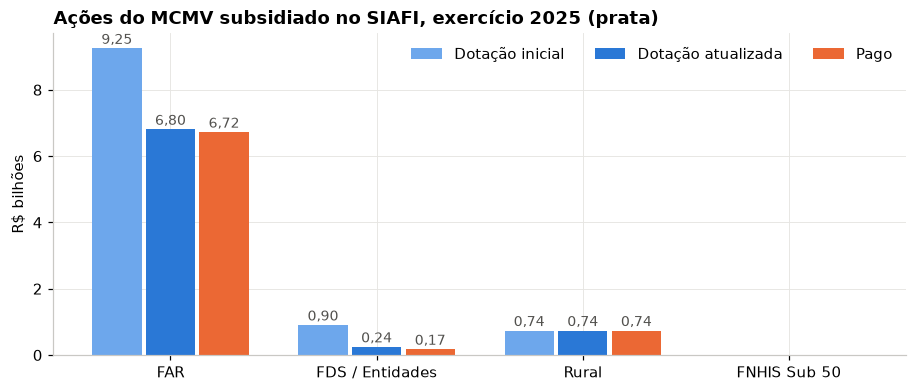

In [4]:
# As quatro ações subsidiadas no mesmo exercício (2025)
fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(ag)); w = 0.26
for i, (col, rot, cor) in enumerate([("dotacao_inicial","Dotação inicial",SEQ[2]),("dotacao_atualizada","Dotação atualizada",C["azul"]),("despesas_pagas","Pago",C["laranja"])]):
    ax.bar(x + (i-1)*w, ag[col]/1e9, w*0.92, label=rot, color=cor)
ax.set_xticks(x); ax.set_xticklabels(ag.index); ax.set_ylabel("R$ bilhões"); ax.legend(ncol=3, loc="upper right")
ax.set_title("Ações do MCMV subsidiado no SIAFI, exercício 2025 (prata)")
rotular_barras(ax, fmt=lambda v: f"{v:.2f}".replace(".", ","))
plt.show()

**Leitura.** Em 2024 a União pôs R$ 7,8 bi no FAR; em 2025, R$ 6,7 bi (a LOA previa R$ 9,25 bi, a dotação foi reduzida para R$ 6,8 bi e quase tudo foi pago); para 2026 a LOA traz R$ 5,8 bi, com meta de 28 mil UH contra 56 mil em 2025. Somando 2024 e 2025, R$ 14,5 bi entraram no fundo, enquanto a carteira contratada do Novo MCMV-FAR soma R$ 25 bi (etapa 3): a diferença é coberta pelo saldo do fundo (prestações das famílias, legado) e pelo cronograma de pagamento por medição, que dilui o desembolso em dois ou três anos. O elo entre o orçamento e a carteira é o saldo do FAR na CAIXA, que não está em nenhuma base do Gov Hub. Para fechar a linha do tempo com o ano corrente, falta a extração anual do Tesouro Gerencial (2024 e 2026 ainda não estão na prata).

## 2. Seleção: do protocolo da proposta à portaria

O mapa da política coloca aqui quatro marcos: portaria de abertura do ciclo, apresentação de propostas, portaria de enquadramento e portaria de aptidão à contratação. A base que enxerga isso é o consolidado do GFAR (`prata.prata_far_consolidado`), uma linha por movimento de proposta, da protocolização à contratação. As propostas em fase 1 ainda não têm APF; só ganham APF quando contratadas (fase 2).

In [5]:
cons = cache("far_consolidado_recente", """
select id_proposta, apf, co_fase, co_etapa, co_status, co_situacao_protocolizada, co_situacao_contratada, portaria_contratacao,
       uf, regiao, municipio, qt_uh, valor_far, valor_contrapartidas, dt_protocolo, dt_recebimento_gfar, dt_vencimento_portaria,
       co_originacao, co_tipo_demanda, co_tipo_edificacao, ic_terreno_doado, co_tipo_proponente
from prata.prata_far_consolidado where ic_na_remessa_mais_recente""")
cons["dt_protocolo"] = pd.to_datetime(cons.dt_protocolo)
prop = cons.sort_values("dt_protocolo").drop_duplicates("id_proposta", keep="last")
print(f"{len(prop):} propostas distintas na remessa mais recente, protocoladas entre {prop.dt_protocolo.min():%d/%m/%Y} e {prop.dt_protocolo.max():%d/%m/%Y}")
print(f"{prop.apf.notna().sum():} com APF (contratadas)  |  {prop.apf.isna().sum():} sem APF (pré-contratual)")
print("UH pedidas nas propostas:", num(prop.qt_uh.sum()), "| valor FAR pedido:", brl(prop.valor_far.sum()))

13307 propostas distintas na remessa mais recente, protocoladas entre 02/07/2023 e 21/08/2026
744 com APF (contratadas)  |  12563 sem APF (pré-contratual)
UH pedidas nas propostas: 1.633.426 | valor FAR pedido: R$ 19,29 bi


### O que é cada coisa no consolidado do GFAR

O consolidado (`TP_CR006_Consolidada_MCID` no MNPO MCMV-FAR 2023, arquivo HIS_MCIDADES_CONSOLIDADO) é a base que a CAIXA manda ao Ministério com todas as propostas, da protocolização à contratação. Os códigos têm dicionário oficial no manual:

**Protocolo.** Uma proposta é protocolada quando o proponente (ente público ou construtora) a apresenta ao agente financeiro com a documentação mínima (terreno, projeto, declaração de compromissos). A partir daí o AF analisa o enquadramento e comunica ao GFAR, que contabiliza a proposta contra a meta da UF. Protocolar não é aprovar: é entrar na fila.

**Fase (`co_fase`).** 1 = Enquadramento (tudo que acontece antes do contrato); 2 = Contratação. Só na fase 2 a proposta tem APF, o número da operação no SIAPF que a CAIXA cria quando contrata; antes disso ela só tem o `id_proposta`.

**Etapa (`co_etapa`).** 1 Enquadramento pelo AF (documentação, terreno, meta); 2 Verificação documental do GFAR; 3 Atualização da meta (há meta na UF?); 4 Enquadramento pelo MCid (proposta enviada ao Ministério); 5 Habilitação para contratação (enquadrada, aguardando meta); 6 Contratação pelo AF.

**Status (`co_status`).** 1 Enquadrada pelo AF; 2 Em análise documental; 3 Em avaliação de terreno; 4 Não enquadrada pelo AF; 5 Reserva não efetuada por pendência documental; 6 Reserva não efetuada, sem meta para a UF; 7 Reserva realizada, enviada para enquadramento; 8 Enquadrada pelo MCid (publicada em portaria de enquadramento); 9 Apta para contratação, enviada ao MCid; 10 Não apta, sem meta na UF; 11 Portaria de contratação publicada, ainda não contratada; 12 Contratada. Na remessa atual a fase 2 usa os códigos 13 a 20 e a fase 1 também traz 17, 19, 21 e 22, nenhum deles no manual de 2023: o layout mudou depois. O 15, com 671 propostas na fase 2, é com quase certeza a "contratada" da versão nova. Pedir ao GFAR o layout vigente do TP_CR006 fecha isso.

**Situação da proposta protocolizada (`co_situacao_protocolizada`).** É a visão do AF na etapa 1: 1 Enquadrada pelo AF; 2 Em análise documental; 3 Em avaliação de terreno; 4 Não enquadrada pelo AF. O código 5, que aparece na base, também não está no manual.

Em resumo: "aceita" tem três degraus (enquadrada pelo AF, enquadrada pelo MCid por portaria, apta à contratação por portaria) e só o quarto degrau, o contrato assinado pelo AF, gera o APF e faz a proposta virar empreendimento na ficha.

,co_fase,etapa_nome,co_status,status_nome,propostas,uh,valor_far
0,1,1 Enquadramento AF,1.000000,Enquadrada AF,9,1.492,R$ 0
1,1,1 Enquadramento AF,2.000000,Em análise documental,949,137.736,R$ 0
2,1,1 Enquadramento AF,3.000000,Em avaliação terreno,710,117.865,R$ 0
3,1,1 Enquadramento AF,4.000000,Não enquadrada AF,6349,719.212,R$ 0
4,1,2 Verificação documental GFAR,5.000000,Reserva não efetuada: pendência documental,437,56.800,R$ 0
5,1,2 Verificação documental GFAR,7.000000,"Reserva realizada, enviada p/ enquadramento",1855,163.452,R$ 0
6,1,2 Verificação documental GFAR,21.000000,código 21 (não documentado),6,750,R$ 0
7,1,4 Enquadramento MCid,17.000000,código 17 (não documentado),269,36.020,R$ 0
8,1,4 Enquadramento MCid,19.000000,código 19 (não documentado),620,100.706,R$ 0
9,1,5 Habilitação p/ contratação,9.000000,"Apta p/ contratação, enviada ao MCid",25,4.197,R$ 0


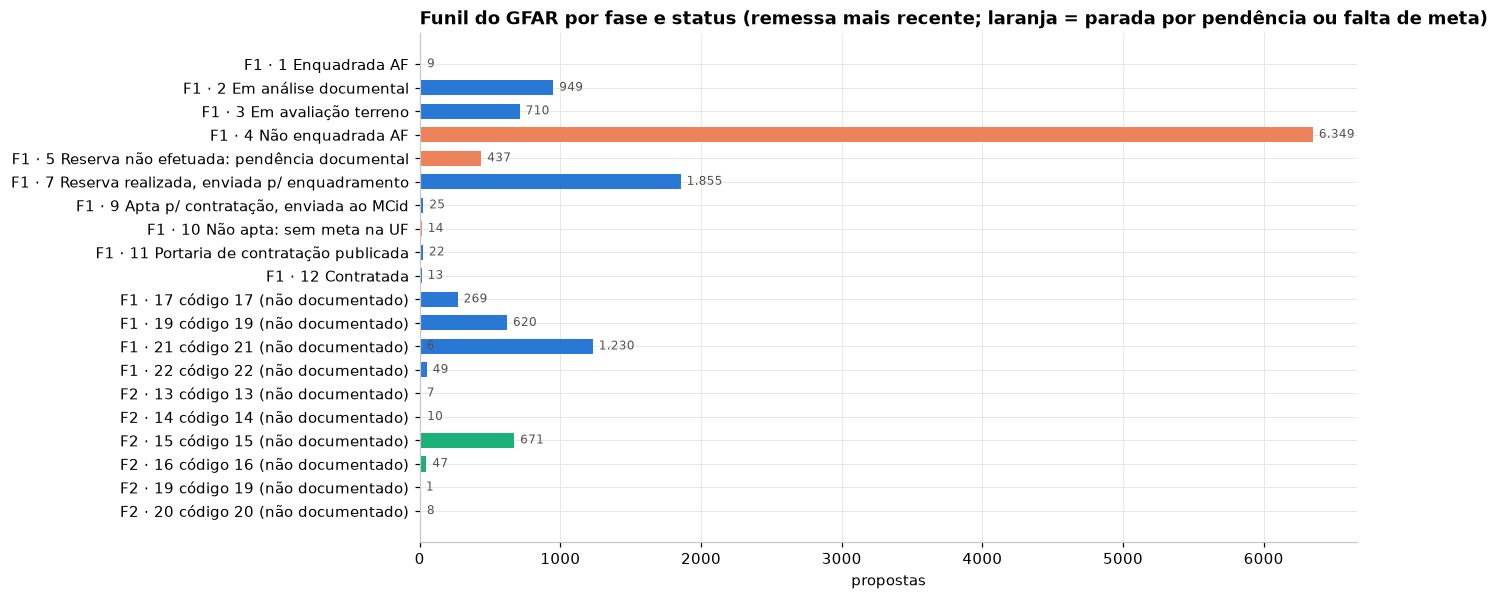

Fase 1 (pré-contratual): 12.563 propostas, 1.514.282 UH pedidas (o valor FAR só é informado depois da contratação)
  das quais paradas por falta de meta na UF (status 6 e 10): 14 | não enquadradas ou com pendência (4 e 5): 6.786
  enquadradas pelo MCid ou aptas (8, 9, 11): 47
Fase 2 (contratadas, com APF): 744


,propostas,uh
sitprot_nome,,
Não enquadrada AF,6355,721471
Enquadrada AF,3313,373400
código 5 (não documentado),1236,163810
Em análise documental,949,137736
Em avaliação terreno,710,117865


In [6]:
# Dicionários do MNPO 2023 e funil por status
STATUS_GFAR = {1:"Enquadrada AF", 2:"Em análise documental", 3:"Em avaliação terreno", 4:"Não enquadrada AF", 5:"Reserva não efetuada: pendência documental",
          6:"Reserva não efetuada: sem meta na UF", 7:"Reserva realizada, enviada p/ enquadramento", 8:"Enquadrada MCid (portaria)", 9:"Apta p/ contratação, enviada ao MCid",
          10:"Não apta: sem meta na UF", 11:"Portaria de contratação publicada", 12:"Contratada"}
ETAPA = {1:"1 Enquadramento AF", 2:"2 Verificação documental GFAR", 3:"3 Atualização da meta", 4:"4 Enquadramento MCid", 5:"5 Habilitação p/ contratação", 6:"6 Contratação"}
SITP = {1:"Enquadrada AF", 2:"Em análise documental", 3:"Em avaliação terreno", 4:"Não enquadrada AF"}
prop["status_nome"] = prop.co_status.map(lambda c: STATUS_GFAR.get(int(c), f"código {int(c)} (não documentado)") if pd.notna(c) else "sem status")
prop["etapa_nome"] = prop.co_etapa.map(lambda c: ETAPA.get(int(c), f"etapa {int(c)}") if pd.notna(c) else "sem etapa")
prop["sitprot_nome"] = prop.co_situacao_protocolizada.map(lambda c: SITP.get(int(c), f"código {int(c)} (não documentado)") if pd.notna(c) else "sem situação")
funil = prop.groupby(["co_fase","etapa_nome","co_status","status_nome"]).agg(propostas=("id_proposta","size"), uh=("qt_uh","sum"), valor_far=("valor_far","sum")).reset_index()
display(funil.style.format({"valor_far": brl, "uh": num}))

ordem = funil.sort_values(["co_fase","co_status"])
fig, ax = plt.subplots(figsize=(11, 6))
labels = [f"F{int(r.co_fase)} · {int(r.co_status)} {r.status_nome}" for r in ordem.itertuples()]
cores = [C["verde"] if r.co_fase == 2 else (STATUS_C["serio"] if int(r.co_status) in (4, 5, 6, 10) else C["azul"]) for r in ordem.itertuples()]
ax.barh(labels, ordem.propostas, color=cores, height=0.65); ax.invert_yaxis(); ax.set_xlabel("propostas")
ax.set_title("Funil do GFAR por fase e status (remessa mais recente; laranja = parada por pendência ou falta de meta)")
rotular_barras(ax, horizontal=True, fontsize=8)
plt.show()
f1 = prop[prop.co_fase == 1]
print(f"Fase 1 (pré-contratual): {num(len(f1))} propostas, {num(f1.qt_uh.sum())} UH pedidas (o valor FAR só é informado depois da contratação)")
print(f"  das quais paradas por falta de meta na UF (status 6 e 10): {num(f1.co_status.isin([6, 10]).sum())} | não enquadradas ou com pendência (4 e 5): {num(f1.co_status.isin([4, 5]).sum())}")
print(f"  enquadradas pelo MCid ou aptas (8, 9, 11): {num(f1.co_status.isin([8, 9, 11]).sum())}")
print(f"Fase 2 (contratadas, com APF): {num((prop.co_fase == 2).sum())}")
display(prop[prop.co_fase == 1].groupby("sitprot_nome").agg(propostas=("id_proposta","size"), uh=("qt_uh","sum")).sort_values("propostas", ascending=False))

<div style="border:2px solid #d03b3b;background:#fff4f4;padding:10px 14px;border-radius:6px;margin:6px 0"><b style="color:#d03b3b">⚠ Fora do banco: dicionários de fase, etapa, status e situação protocolizada do GFAR</b><ul style="margin:6px 0 0 0"><li>Os nomes dos códigos (<code>STATUS_GFAR</code>, <code>ETAPA</code>, <code>SITP</code>) foram transcritos do MNPO MCMV-FAR 2023 (leiaute TP_CR006 Consolidada MCID), arquivo <code>mnpo_far_2023.txt</code> na pasta de fontes. Não existem no banco.</li><li>Os códigos 13 a 22 que aparecem na remessa atual não estão no manual de 2023: continuam sem nome.</li><li><b>Como levar ao banco:</b> criar as seeds <code>far_gfar_fase.csv</code>, <code>far_gfar_etapa.csv</code>, <code>far_gfar_status.csv</code> e <code>far_gfar_situacao_protocolizada.csv</code> (codigo, nome, descricao, fonte, vigencia) em <code>dbt/mcid/seeds/</code>, no mesmo padrão de <code>far_situacao_obra.csv</code>, e pedir ao GFAR o leiaute vigente para completar os códigos novos.</li></ul></div>

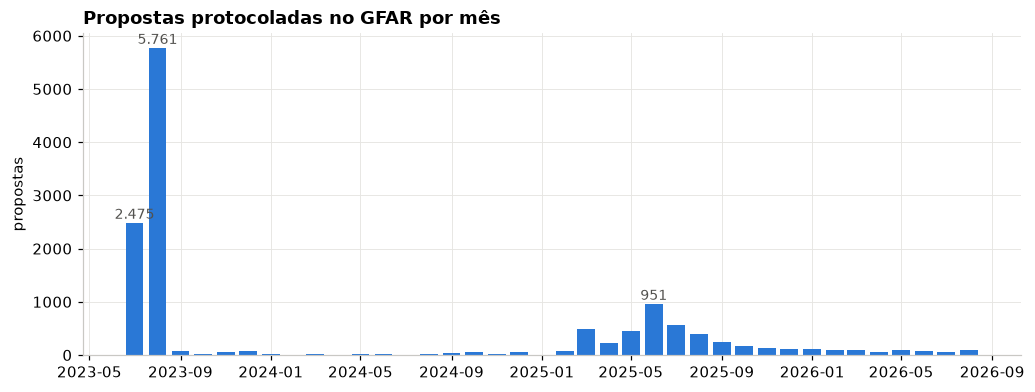

Meses com mais protocolos:


,propostas,uh
dt_protocolo,,
2023-08-01,5761,596589
2023-07-01,2475,325075
2025-06-01,951,150949
2025-07-01,570,86444
2025-03-01,495,32385


In [7]:
# Ritmo de entrada de propostas por mês de protocolo
m = prop.set_index("dt_protocolo").resample("MS").agg(propostas=("id_proposta","size"), uh=("qt_uh","sum"))
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(m.index, m.propostas, width=24, color=C["azul"])
ax.set_title("Propostas protocoladas no GFAR por mês"); ax.set_ylabel("propostas")
for d, v in m.propostas.nlargest(3).items():
    ax.annotate(num(v), (d, v), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9, color="#52514e")
plt.show()
print("Meses com mais protocolos:"); display(m.propostas.nlargest(5).rename("propostas").to_frame().assign(uh=m.uh))

### As portarias e os empreendimentos sem portaria

As portarias são o instrumento pelo qual o Ministério abre o ciclo, enquadra e declara a aptidão. Na carteira contratada, a ficha do empreendimento traz a **portaria de seleção** de cada APF. A `Portaria MCID nº 727, de 2023` abriu o primeiro ciclo do Novo MCMV; a `488, de 2025` substituiu a 727 no ciclo 2025/26 (e prorrogou propostas pela regra do art. 14); a `47, de 2025` e a `704, de 2024` são portarias específicas (calamidade e agravamento). "Não informada" são 84 APFs sem a portaria na base da CAIXA.

A ideia de distribuir os sem portaria pela data funciona porque cada portaria define uma janela de contratação. Abaixo: a janela de cada portaria pela data de contratação, um KMeans sobre as datas para ver se os grupos naturais coincidem com as portarias, e a atribuição dos 84 pela portaria dos vizinhos mais próximos na data (k vizinhos). O resultado vira a coluna `portaria_final`, usada daqui em diante.

<div style="border:2px solid #d03b3b;background:#fff4f4;padding:10px 14px;border-radius:6px;margin:6px 0"><b style="color:#d03b3b">⚠ Fora do banco: o que cada portaria é, e a portaria atribuída aos 84 APFs</b><ul style="margin:6px 0 0 0"><li>Os rótulos de portaria (727/2023, 488/2025, 47/2025, 704/2024) vêm da ficha (banco). O que cada uma significa (abertura do ciclo 2023, ciclo 2025/26, art. 14, calamidade, agravamento) vem da pesquisa do mapeamento da política, não do banco.</li><li>A coluna <code>portaria_final</code> é uma imputação feita aqui (vizinhos mais próximos na data de contratação; KMeans só de conferência). Não existe no banco.</li><li><b>Como levar ao banco:</b> (a) seed <code>far_portaria_ciclo.csv</code> (portaria, data, ciclo, descricao, janela_contratacao); (b) na <code>prata.prata_far_empreendimento</code>, coluna <code>portaria_selecao_imputada</code> com flag <code>ic_portaria_imputada</code>, pela regra da janela de datas; melhor ainda, trazer a portaria pelo <code>id_proposta</code> do consolidado do GFAR, que é a fonte oficial.</li></ul></div>

,min,max,count
portaria_curta,,,
"Port. 727, de 2023",2024-02-02,2025-07-17,734
Não informada,2024-07-26,2025-06-13,84
"Port. 488, de 2025 (art. 14)",2025-11-28,2026-07-16,2
"Port. 488, de 2025",2025-12-22,2026-08-19,53
"Port. 47, de 2025",2026-02-04,2026-06-05,5


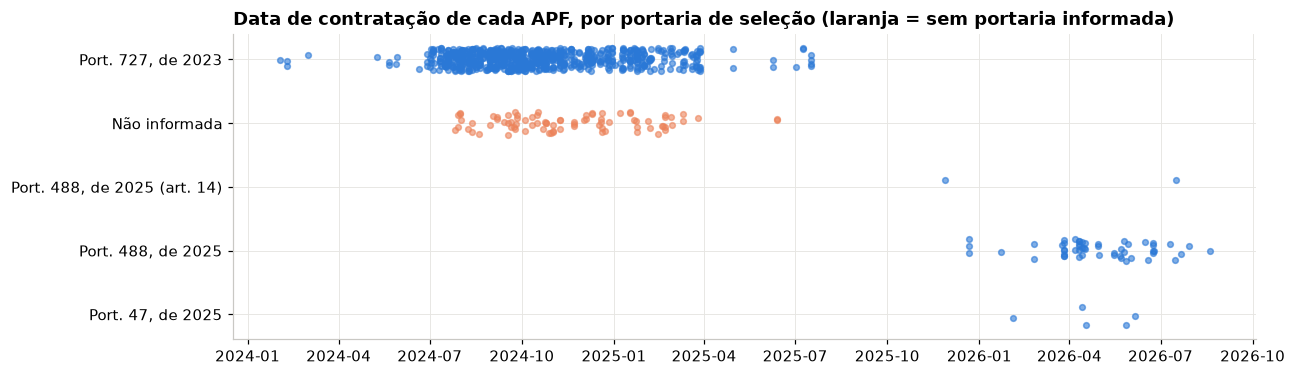

In [8]:
ficha = cache("far_ficha", "select * from ouro.ouro_far_ficha_empreendimento")
for c in ["dt_contratacao","dt_previsao_entrega","dt_conclusao_obra","dt_entrega"]:
    ficha[c] = pd.to_datetime(ficha[c])
cad = cache("far_cadastro_pj", "select apf, construtora_nome, construtora_cnpj, dt_contratacao as dt_contratacao_cad, dt_inicio_obra, dt_previsao_conclusao, dt_apresentacao_orcamento, vr_emprestimo_far, vr_total_investimento from prata.prata_far_cadastro_pj")
for c in ["dt_contratacao_cad","dt_inicio_obra","dt_previsao_conclusao","dt_apresentacao_orcamento"]:
    cad[c] = pd.to_datetime(cad[c])
ficha = ficha.merge(cad, on="apf", how="left")
ficha["portaria_curta"] = ficha.portaria_selecao.str.replace("Portaria MCID nº ", "Port. ").str.replace(" (Art. 14, prorrogadas da 727/2023)", " (art. 14)")
jan = ficha.groupby("portaria_curta").dt_contratacao.agg(["min","max","count"]).sort_values("min")
display(jan)
fig, ax = plt.subplots(figsize=(12, 3.6))
ordem = jan.index.tolist()
for i, p in enumerate(ordem):
    d = ficha.loc[ficha.portaria_curta == p, "dt_contratacao"]
    ax.scatter(d, np.full(len(d), i) + np.random.uniform(-0.18, 0.18, len(d)), s=14, alpha=0.6, color=STATUS_C["serio"] if "Não" in p else C["azul"])
ax.set_yticks(range(len(ordem))); ax.set_yticklabels(ordem); ax.invert_yaxis()
ax.set_title("Data de contratação de cada APF, por portaria de seleção (laranja = sem portaria informada)")
plt.show()

In [9]:
# Os grupos naturais das datas (KMeans) coincidem com as portarias?
from sklearn.cluster import KMeans
from sklearn.neighbors import KNeighborsClassifier
X = ((ficha.dt_contratacao - pd.Timestamp("2024-01-01")).dt.days.values.reshape(-1, 1)).astype(float)
km = KMeans(n_clusters=3, n_init=10, random_state=0).fit(X)
ficha["cluster_data"] = km.labels_
ordem_cl = ficha.groupby("cluster_data").dt_contratacao.min().sort_values().index
ficha["cluster_data"] = ficha.cluster_data.map({c: i + 1 for i, c in enumerate(ordem_cl)})
display(pd.crosstab(ficha.portaria_curta, ficha.cluster_data, margins=True))
print("Janela de cada cluster:"); display(ficha.groupby("cluster_data").dt_contratacao.agg(["min","max","count"]))

# Atribuição dos 84 sem portaria: portaria dos k vizinhos mais próximos na data de contratação
conhecidas = ficha[ficha.portaria_selecao != "Não informada"]
knn = KNeighborsClassifier(n_neighbors=7).fit(X[conhecidas.index], conhecidas.portaria_selecao)
sem = ficha.portaria_selecao == "Não informada"
ficha["portaria_final"] = ficha.portaria_selecao
ficha.loc[sem, "portaria_final"] = knn.predict(X[ficha.index[sem]])
ficha["portaria_final_curta"] = ficha.portaria_final.str.replace("Portaria MCID nº ", "Port. ").str.replace(" (Art. 14, prorrogadas da 727/2023)", " (art. 14)")
ficha["portaria_imputada"] = sem
print("Portaria atribuída aos 84 sem informação:"); display(ficha.loc[sem].groupby("portaria_final_curta").agg(apfs=("apf","size"), uh=("quantidade_uh","sum"), primeira=("dt_contratacao","min"), ultima=("dt_contratacao","max")))
port = ficha.groupby("portaria_final_curta").agg(empreendimentos=("apf","size"), imputados=("portaria_imputada","sum"), uh=("quantidade_uh","sum"), contratado=("valor_contratado","sum"), desembolsado=("valor_desembolsado","sum"), exec_media=("percentual_execucao_fisica","mean")).sort_values("empreendimentos", ascending=False)
port["pct_desembolsado"] = 100*port.desembolsado/port.contratado
port.style.format({"contratado": brl, "desembolsado": brl, "exec_media": "{:.1f}%", "pct_desembolsado": "{:.1f}%", "uh": num})

cluster_data,1,2,3,All
portaria_curta,,,,
Não informada,45,39,0,84
"Port. 47, de 2025",0,0,5,5
"Port. 488, de 2025",0,0,53,53
"Port. 488, de 2025 (art. 14)",0,0,2,2
"Port. 727, de 2023",517,217,0,734
All,562,256,60,878


Janela de cada cluster:


,min,max,count
cluster_data,,,
1,2024-02-02,2024-11-14,562
2,2024-11-18,2025-07-17,256
3,2025-11-28,2026-08-19,60


Portaria atribuída aos 84 sem informação:


,apfs,uh,primeira,ultima
portaria_final_curta,,,,
"Port. 727, de 2023",84,12451,2024-07-26,2025-06-13


,empreendimentos,imputados,uh,contratado,desembolsado,exec_media,pct_desembolsado
portaria_final_curta,,,,,,,
"Port. 727, de 2023",818,84,122.686,"R$ 23,33 bi","R$ 9,77 bi",52.8%,41.9%
"Port. 488, de 2025",53,0,8.243,"R$ 1,45 bi","R$ 189,79 mi",12.8%,13.1%
"Port. 47, de 2025",5,0,570,"R$ 102,81 mi","R$ 13,74 mi",18.7%,13.4%
"Port. 488, de 2025 (art. 14)",2,0,336,"R$ 71,08 mi","R$ 20,26 mi",25.1%,28.5%


**Leitura.** Os 84 APFs sem portaria foram contratados entre julho de 2024 e junho de 2025, dentro da janela da 727/2023 (fevereiro de 2024 a julho de 2025) e antes da primeira contratação da 488/2025 (dezembro de 2025). O KMeans sobre as datas separa três blocos (o ciclo 2023, a transição de 2025 e o ciclo 2025/26), e os vizinhos mais próximos põem os 84 na 727/2023. O KMeans serve de conferência, não de regra: a regra é a janela da portaria. Para fechar sem ambiguidade, a data de protocolo da proposta no consolidado (`dt_protocolo`) e a `portaria_contratacao` do GFAR seriam melhores do que a data de contratação, mas esses 84 APFs não aparecem no consolidado com portaria.

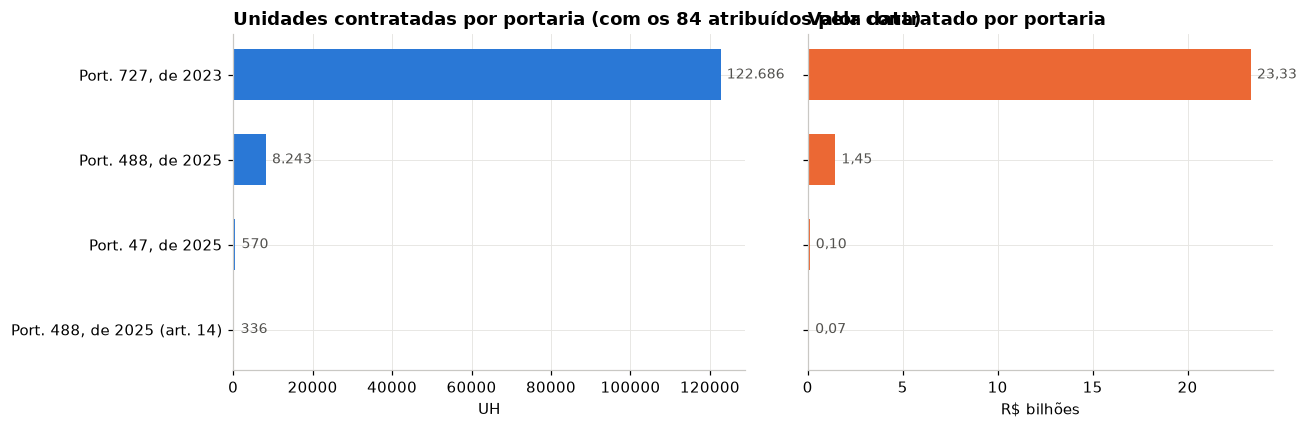

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1.1, 1]})
p = port.sort_values("uh")
axes[0].barh(p.index, p.uh, color=C["azul"], height=0.6); axes[0].set_title("Unidades contratadas por portaria (com os 84 atribuídos pela data)"); axes[0].set_xlabel("UH")
rotular_barras(axes[0], horizontal=True)
axes[1].barh(p.index, p.contratado/1e9, color=C["laranja"], height=0.6); axes[1].set_title("Valor contratado por portaria"); axes[1].set_xlabel("R$ bilhões")
rotular_barras(axes[1], fmt=lambda v: f"{v:.2f}".replace(".", ","), horizontal=True)
axes[1].set_yticklabels([])
plt.tight_layout(); plt.show()

## 3. Contratação: a carteira do Novo MCMV-FAR

Depois da portaria de aptidão, o agente financeiro contrata em nome do FAR, com a construtora e o ente público, em até 120 dias. A partir daqui o empreendimento tem APF e passa a existir na ficha (`ouro.ouro_far_ficha_empreendimento`, uma linha por APF).

In [11]:
tot = dict(n=len(ficha), uh=ficha.quantidade_uh.sum(), pessoas=ficha.pessoas_atendidas.sum(), contratado=ficha.valor_contratado.sum(),
           desembolsado=ficha.valor_desembolsado.sum(), ufs=ficha.uf.nunique(), municipios=ficha.municipio_uf.nunique())
print(f"Empreendimentos contratados: {tot['n']}  |  UH: {num(tot['uh'])}  |  pessoas a atender (estimativa da ficha): {num(tot['pessoas'])}")
print(f"Valor contratado: {brl(tot['contratado'])}  |  desembolsado: {brl(tot['desembolsado'])} ({100*tot['desembolsado']/tot['contratado']:.1f}%)")
print(f"Valor médio por UH: {brl(tot['contratado']/tot['uh'])}  |  UFs: {tot['ufs']}  |  municípios: {tot['municipios']}")
print(f"Contratações de {ficha.dt_contratacao.min():%d/%m/%Y} a {ficha.dt_contratacao.max():%d/%m/%Y}")

Empreendimentos contratados: 878  |  UH: 131.835  |  pessoas a atender (estimativa da ficha): 434.819
Valor contratado: R$ 24,96 bi  |  desembolsado: R$ 10,00 bi (40.1%)
Valor médio por UH: R$ 189,30 mil  |  UFs: 27  |  municípios: 384
Contratações de 02/02/2024 a 19/08/2026


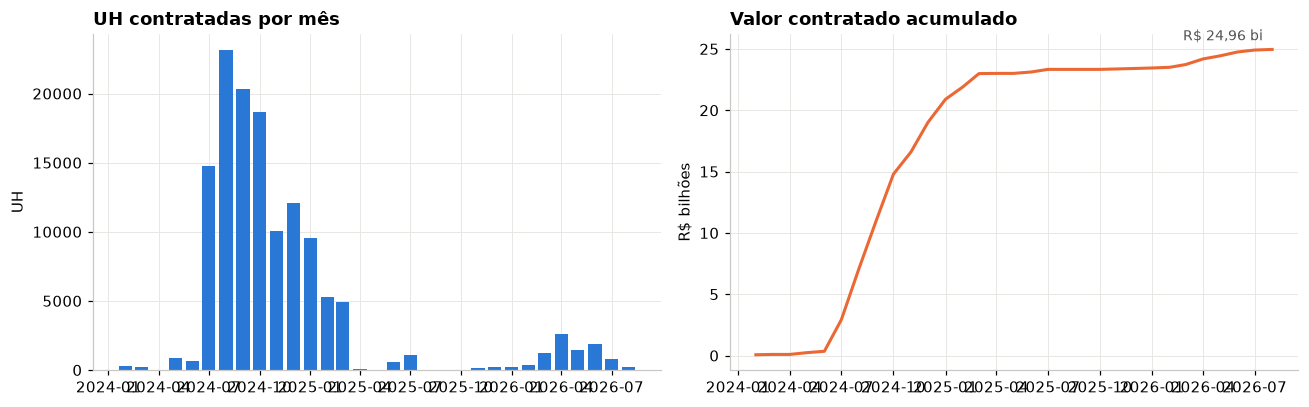

Meses de maior contratação (UH):


,uh
dt_contratacao,
2024-08-01,23141
2024-09-01,20350
2024-10-01,18689
2024-07-01,14794
2024-12-01,12048


In [12]:
# Ritmo de contratação: UH contratadas por mês e acumulado
mc = ficha.set_index("dt_contratacao").resample("MS").agg(empreendimentos=("apf","size"), uh=("quantidade_uh","sum"), valor=("valor_contratado","sum"))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(mc.index, mc.uh, width=24, color=C["azul"]); axes[0].set_title("UH contratadas por mês"); axes[0].set_ylabel("UH")
axes[1].plot(mc.index, mc.valor.cumsum()/1e9, color=C["laranja"], lw=2); axes[1].set_title("Valor contratado acumulado"); axes[1].set_ylabel("R$ bilhões")
axes[1].annotate(brl(mc.valor.sum()), (mc.index[-1], mc.valor.sum()/1e9), xytext=(-6, 6), textcoords="offset points", ha="right", fontsize=9, color="#52514e")
plt.tight_layout(); plt.show()
print("Meses de maior contratação (UH):"); display(mc.uh.nlargest(5).to_frame())

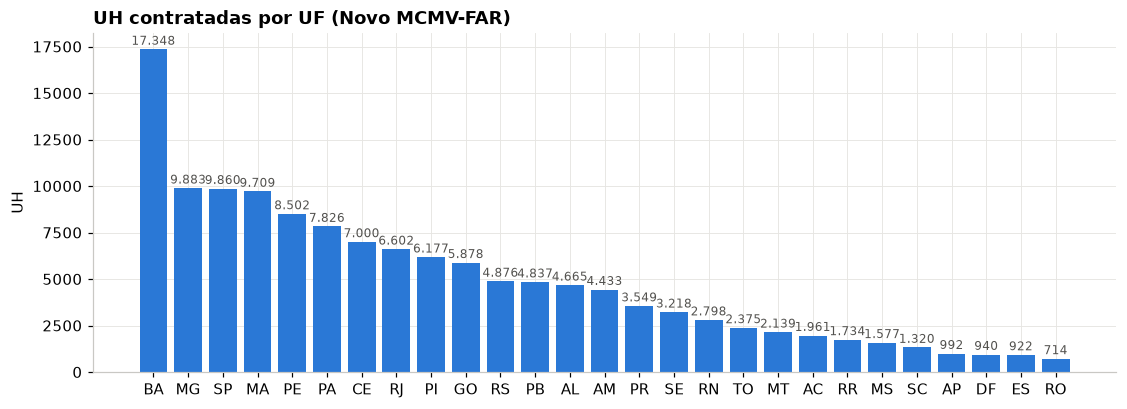

As 5 maiores UFs concentram 42% das UH e 41% do valor contratado: BA, MG, SP, MA, PE


In [13]:
# Onde está a carteira: UH e valor por UF
uf = ficha.groupby("uf").agg(empreendimentos=("apf","size"), uh=("quantidade_uh","sum"), contratado=("valor_contratado","sum"), desembolsado=("valor_desembolsado","sum"), exec_media=("percentual_execucao_fisica","mean")).sort_values("uh", ascending=False)
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(uf.index, uf.uh, color=C["azul"]); ax.set_title("UH contratadas por UF (Novo MCMV-FAR)"); ax.set_ylabel("UH")
rotular_barras(ax, fontsize=8)
plt.show()
top5 = uf.head(5)
print(f"As 5 maiores UFs concentram {100*top5.uh.sum()/uf.uh.sum():.0f}% das UH e {100*top5.contratado.sum()/uf.contratado.sum():.0f}% do valor contratado:", ", ".join(top5.index))

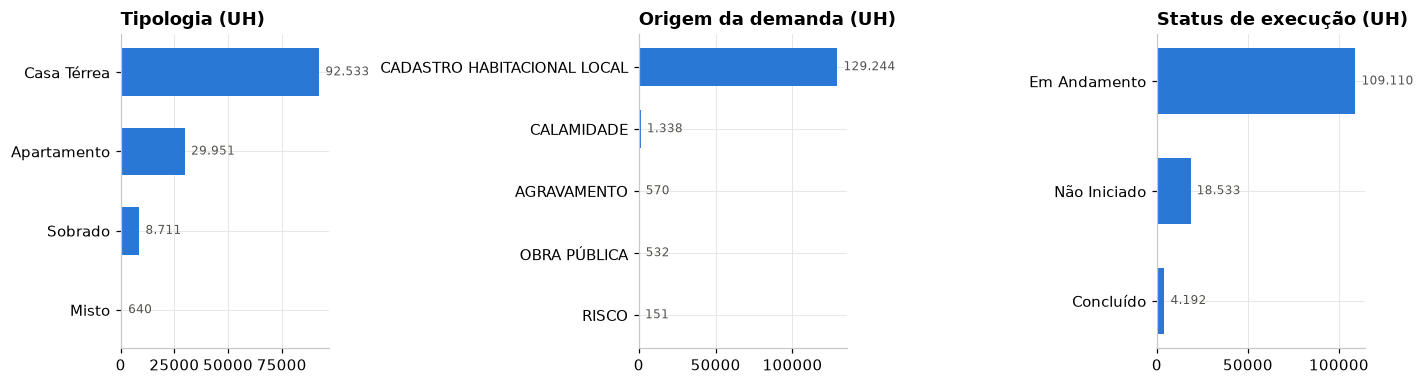

In [14]:
# Como é o empreendimento: tipologia, demanda, método
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col, titulo in zip(axes, ["tipologia","demanda","status_execucao_simplificado"], ["Tipologia (UH)","Origem da demanda (UH)","Status de execução (UH)"]):
    s = ficha.groupby(col).quantidade_uh.sum().sort_values()
    ax.barh(s.index, s.values, color=C["azul"], height=0.6); ax.set_title(titulo)
    rotular_barras(ax, horizontal=True, fontsize=8)
plt.tight_layout(); plt.show()

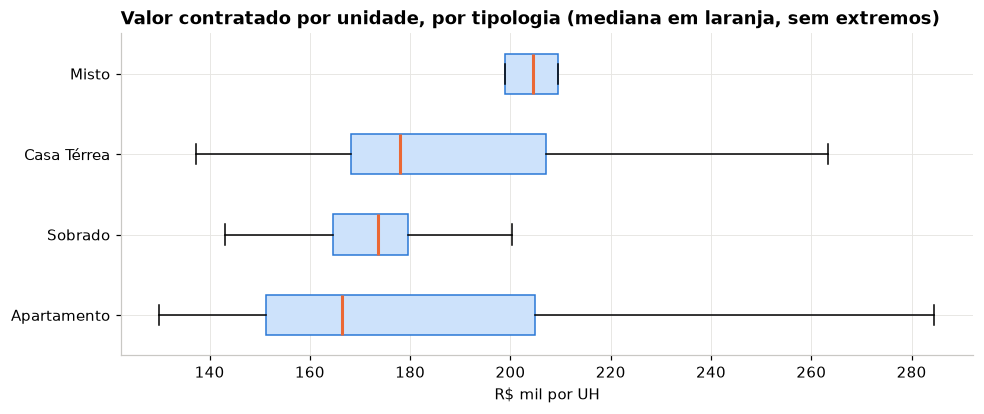

,count,25%,50%,75%
tipologia,,,,
Apartamento,253.000000,"R$ 151,19 mil","R$ 166,44 mil","R$ 204,83 mil"
Casa Térrea,558.000000,"R$ 168,26 mil","R$ 177,88 mil","R$ 207,10 mil"
Misto,5.000000,"R$ 198,97 mil","R$ 204,43 mil","R$ 209,57 mil"
Sobrado,62.000000,"R$ 164,63 mil","R$ 173,56 mil","R$ 179,53 mil"


In [15]:
# Custo por UH, por tipologia
fig, ax = plt.subplots(figsize=(10, 3.8))
ordem = ficha.groupby("tipologia").valor_por_uh.median().sort_values().index
dados = [ficha.loc[ficha.tipologia == t, "valor_por_uh"].dropna()/1e3 for t in ordem]
bp = ax.boxplot(dados, tick_labels=ordem, vert=False, widths=0.5, patch_artist=True, showfliers=False)
for b in bp["boxes"]: b.set(facecolor="#cde2fb", edgecolor=C["azul"])
for k in ["medians"]:
    for l in bp[k]: l.set(color=C["laranja"], lw=2)
ax.set_xlabel("R$ mil por UH"); ax.set_title("Valor contratado por unidade, por tipologia (mediana em laranja, sem extremos)")
plt.show()
display(ficha.groupby("tipologia").valor_por_uh.describe()[["count","25%","50%","75%"]].style.format(brl, subset=["25%","50%","75%"]))

### Contrapartidas pactuadas pelos entes

O mapa marca, na contratação, as contrapartidas obrigatórias do ente público (terreno, infraestrutura externa, equipamentos públicos, isenção de ITBI e ITCMD). O secretário destacou que a pactuação do termo de anuência não está tabulada na SNH. O que o Gov Hub tem é o que a CAIXA informa no cadastro PJ (`ouro.ouro_far_contrapartida`).

,ente,tipo,empreendimentos,valor
5,Município,Terreno,352,"R$ 1,12 bi"
4,Município,Infraestrutura,536,"R$ 523,59 mi"
3,Município,Complementar,138,"R$ 369,53 mi"
2,Estado,Terreno,49,"R$ 345,71 mi"
0,Estado,Complementar,83,"R$ 314,38 mi"
6,Outros,Outras,308,"R$ 284,28 mi"
1,Estado,Infraestrutura,47,"R$ 119,35 mi"


Empreendimentos com alguma contrapartida informada: 814 de 878 (93%)  |  valor total: R$ 3,08 bi


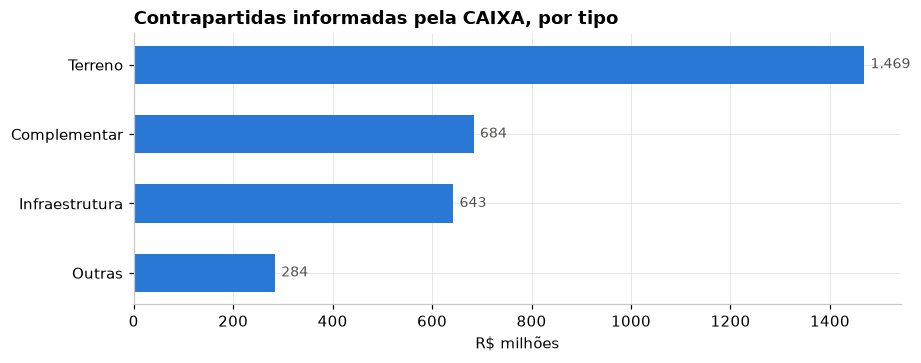

In [16]:
contra = cache("far_contrapartida", "select * from ouro.ouro_far_contrapartida")
ct = contra.groupby(["ente","tipo"]).agg(empreendimentos=("apf","nunique"), valor=("valor","sum")).reset_index().sort_values("valor", ascending=False)
display(ct.style.format({"valor": brl}))
print(f"Empreendimentos com alguma contrapartida informada: {contra.apf.nunique()} de {len(ficha)} ({100*contra.apf.nunique()/len(ficha):.0f}%)  |  valor total: {brl(contra.valor.sum())}")
fig, ax = plt.subplots(figsize=(9, 3.2))
s = contra.groupby("tipo").valor.sum().sort_values()
ax.barh(s.index, s.values/1e6, color=C["azul"], height=0.55); ax.set_xlabel("R$ milhões"); ax.set_title("Contrapartidas informadas pela CAIXA, por tipo")
rotular_barras(ax, fmt=lambda v: f"{v:,.0f}".replace(",", "."), horizontal=True)
plt.show()

## 4. Execução: como estão as obras no Brasil

Aqui o mapa fala em execução e medição da obra, vistoria e atestado de avanço. Os dados respondem com três lentes, na ordem que o secretário pediu: primeiro a **situação na língua da CAIXA**, depois o **percentual de execução física**, e só então a **curva S**.

,empreendimentos,uh,contratado,desembolsado
situacao_empreendimento,,,,
EM ANDAMENTO,777,117.360,"R$ 22,31 bi","R$ 9,71 bi"
DISTRATADO/CANCELADO,78,11.460,"R$ 2,06 bi","R$ 2,16 mi"
CONCLUÍDO E ENTREGUE,17,1.947,"R$ 325,34 mi","R$ 276,23 mi"
PARALISADO,5,828,"R$ 206,87 mi","R$ 10,66 mi"
Situação não mapeada,1,240,"R$ 49,82 mi",R$ 0


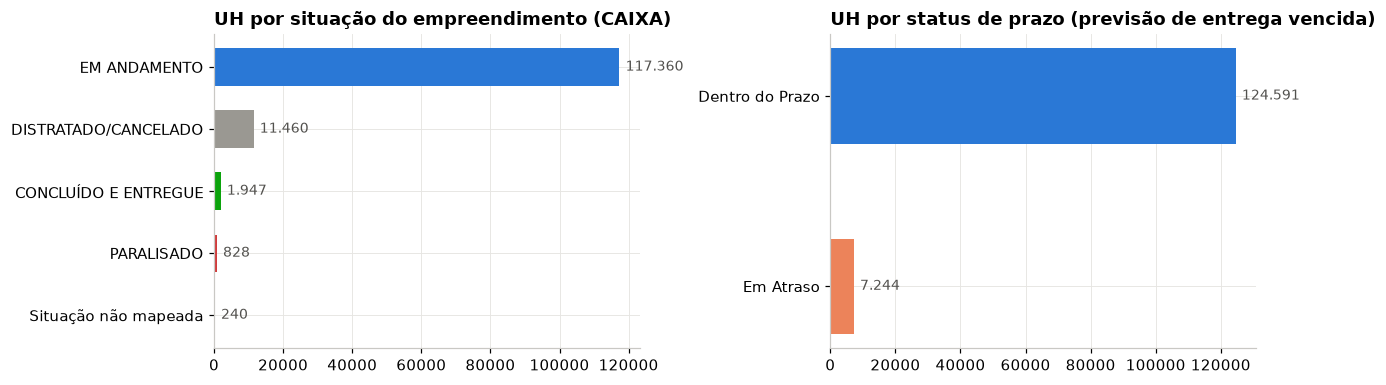

In [17]:
# Situação do empreendimento (CAIXA) e status de prazo
sit = ficha.groupby("situacao_empreendimento").agg(empreendimentos=("apf","size"), uh=("quantidade_uh","sum"), contratado=("valor_contratado","sum"), desembolsado=("valor_desembolsado","sum")).sort_values("uh", ascending=False)
display(sit.style.format({"contratado": brl, "desembolsado": brl, "uh": num}))
COR_SIT = {"EM ANDAMENTO": C["azul"], "CONCLUÍDO E ENTREGUE": STATUS["bom"], "PARALISADO": STATUS["critico"], "DISTRATADO/CANCELADO": STATUS["neutro"], "Situação não mapeada": "#d6d5d1"}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
s = sit.uh.sort_values()
axes[0].barh(s.index, s.values, color=[COR_SIT.get(i, C["cinza"]) for i in s.index], height=0.6); axes[0].set_title("UH por situação do empreendimento (CAIXA)")
rotular_barras(axes[0], horizontal=True)
sp = ficha.groupby("status_prazo").agg(uh=("quantidade_uh","sum")).uh.sort_values()
axes[1].barh(sp.index, sp.values, color=[STATUS["serio"] if "Atraso" in i else C["azul"] for i in sp.index], height=0.5); axes[1].set_title("UH por status de prazo (previsão de entrega vencida)")
rotular_barras(axes[1], horizontal=True)
plt.tight_layout(); plt.show()

,NORMAL,OBRA NAO INICIADA,EM ATENCAO,RISCO DE PARALISACAO,PARALISADO,OBRA RETOMADA,OBRA SOLUCIONADA,TRATAMENTO CUSTOMIZADO,CRONOGRAMA INCOMPLETO,SEM INFORMACAO,DISTRATADO (CAIXA),total
anomes,,,,,,,,,,,,
202512,447,147,174,1,0,0,2,0,0,2,46,819
202601,433,133,204,1,0,0,4,0,0,1,72,848
202602,399,103,236,1,0,0,6,0,0,5,72,822
202604,281,88,371,1,2,0,10,3,0,5,77,838
202605,288,74,378,2,4,0,11,3,3,5,77,845
202606,291,62,388,3,4,0,17,3,1,5,78,852
202607,315,55,385,4,2,2,25,3,0,4,78,873
202608,322,43,374,11,3,2,11,3,9,22,0,800


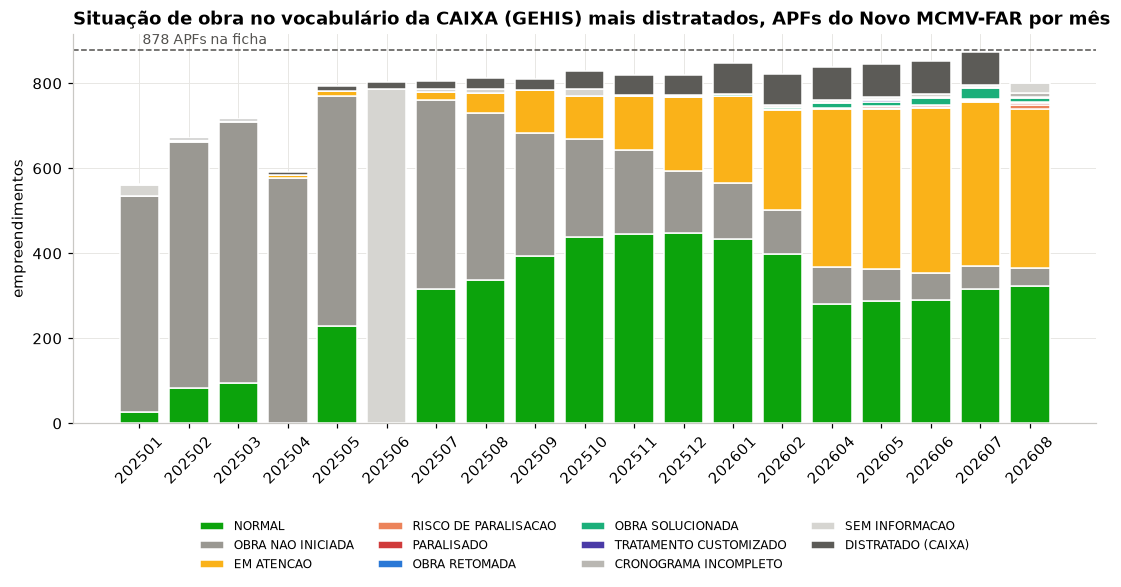

Último mês (202608): NORMAL 322; OBRA NAO INICIADA 43; EM ATENCAO 374; RISCO DE PARALISACAO 11; PARALISADO 3; OBRA RETOMADA 2; OBRA SOLUCIONADA 11; TRATAMENTO CUSTOMIZADO 3; CRONOGRAMA INCOMPLETO 9; SEM INFORMACAO 22; total 800


In [18]:
# A língua da CAIXA: situação de obra no acompanhamento semanal GEHIS, por mês (último retrato de cada mês), só APFs do FAR novo,
# mais os distratados (que saem do GEHIS) contados pelo retrato mensal da CAIXA
gehis = cache("far_gehis_mensal", """
with g as (
  select nu_apf as apf, coalesce(nullif(nu_anomes,''), anomes) as anomes, upper(trim(situacao_obra)) as situacao, _source_file
  from bronze.bronze_sftp_gehis_andamento_obra
  where nu_apf ~ '^[0-9]{8}$' and coalesce(nullif(nu_anomes,''), anomes) ~ '^20[0-9]{4}$'
), ult as (select anomes, max(_source_file) as arq from g group by anomes)
select g.apf, g.anomes, g.situacao from g join ult on ult.anomes = g.anomes and ult.arq = g._source_file
where g.apf in (select apf from ouro.ouro_far_ficha_empreendimento)""")
gehis["situacao"] = gehis.situacao.str.replace("Ç","C").str.replace("Ã","A").str.replace("INAOMPLETO","INCOMPLETO").replace({"": "SEM INFORMACAO"})
cx = cache("far_caixa_serie", """
select apf, competencia, situacao, pct_execucao, valor_desembolsado, uh_contratadas, uh_entregues
from prata.prata_far_caixa_serie where apf in (select apf from ouro.ouro_far_ficha_empreendimento)""")
cx["competencia"] = pd.to_datetime(cx.competencia); cx["anomes"] = cx.competencia.dt.strftime("%Y%m")
dist = cx[cx.situacao == "DISTRATADO/CANCELADO"].groupby("anomes").apf.nunique().rename("DISTRATADO (CAIXA)")

ORDEM = ["NORMAL","OBRA NAO INICIADA","EM ATENCAO","RISCO DE PARALISACAO","PARALISADO","OBRA RETOMADA","OBRA SOLUCIONADA","TRATAMENTO CUSTOMIZADO","CRONOGRAMA INCOMPLETO","SEM INFORMACAO","DISTRATADO (CAIXA)"]
COR_G = {"NORMAL": STATUS_C["bom"], "OBRA NAO INICIADA": C["cinza"], "EM ATENCAO": STATUS_C["atencao"], "RISCO DE PARALISACAO": STATUS_C["serio"], "PARALISADO": STATUS_C["critico"],
         "OBRA RETOMADA": C["azul"], "OBRA SOLUCIONADA": C["verde"], "TRATAMENTO CUSTOMIZADO": C["roxo"], "CRONOGRAMA INCOMPLETO": "#b9b7b2", "SEM INFORMACAO": "#d6d5d1", "DISTRATADO (CAIXA)": "#5c5b57"}
tab = gehis.pivot_table(index="anomes", columns="situacao", values="apf", aggfunc="nunique").fillna(0)
tab = tab.join(dist, how="left").fillna(0)
tab = tab[[c for c in ORDEM if c in tab.columns]]
tab = tab[tab.index >= "202501"]
tab["total"] = tab.sum(axis=1)
display(tab.astype(int).tail(8))
fig, ax = plt.subplots(figsize=(12, 4.6))
bottom = np.zeros(len(tab))
for c in tab.columns.drop("total"):
    ax.bar(tab.index, tab[c], bottom=bottom, color=COR_G[c], label=c, width=0.8, edgecolor="white", linewidth=1)
    bottom += tab[c].values
ax.axhline(len(ficha), color="#52514e", lw=1, ls="--"); ax.annotate(f"{len(ficha)} APFs na ficha", (0, len(ficha)), xytext=(2, 4), textcoords="offset points", fontsize=9, color="#52514e")
ax.set_title("Situação de obra no vocabulário da CAIXA (GEHIS) mais distratados, APFs do Novo MCMV-FAR por mês"); ax.set_ylabel("empreendimentos")
ax.legend(ncol=4, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.22)); plt.xticks(rotation=45)
plt.show()
ult = tab.iloc[-1]
print(f"Último mês ({tab.index[-1]}): " + "; ".join(f"{k} {int(v)}" for k, v in ult.items() if v > 0))

**Por que o GEHIS mostra menos de 800 obras se a ficha tem 878.** O GEHIS acompanha obra em execução: quem foi distratado ou cancelado (78 APFs, R$ 2,06 bi contratados e quase nada desembolsado) sai do arquivo, e parte dos concluídos também. Somando os distratados contados pelo retrato mensal da CAIXA, o total mensal chega perto dos 878 da ficha (linha tracejada); o que falta são obras concluídas e entregues e retratos incompletos de alguns meses (junho de 2026 veio sem situação informada, agosto cobre menos APFs). Ou seja: a carteira "ativa" do Novo MCMV-FAR é de cerca de 790 obras, não 878.

**O que é "em atenção".** É um status interno da CAIXA no acompanhamento de obra da GEHIS, anterior ao "risco de paralisação" e ao "paralisado". O manual não publica o critério, mas o secretário o descreveu como o estado intermediário que a CAIXA usa quando a obra sai do ritmo normal (medições abaixo do cronograma, pendências com a construtora ou com o ente, dificuldade de medição) e antes de configurar paralisação pela regra dos 90 dias sem repasse ou medição. Os dados confirmam essa leitura na próxima seção: as obras "em atenção" estão em média 4,6 pontos abaixo do cronograma vigente, enquanto as "normais" estão 5,6 pontos acima.

<div style="border:2px solid #d03b3b;background:#fff4f4;padding:10px 14px;border-radius:6px;margin:6px 0"><b style="color:#d03b3b">⚠ Fora do banco: o significado de "em atenção" e a normalização do GEHIS</b><ul style="margin:6px 0 0 0"><li>A explicação do que é "em atenção" não vem do banco nem do manual: vem da reunião com o secretário (13/10/2026) e é confirmada só indiretamente pelos desvios medidos na seção seguinte.</li><li>A unificação das grafias (EM ATENÇÃO e EM ATENCAO, "INÃOMPLETO") e o rótulo SEM INFORMACAO para situação vazia são regras deste notebook.</li><li><b>Como levar ao banco:</b> criar <code>prata.prata_far_gehis_andamento_obra</code> (APF normalizado, mês de referência, um arquivo por mês, situação com grafia única), como já existe para o Rural; e a seed <code>dominio_gehis_situacao.csv</code> (situacao, descricao, ordem de gravidade), com as descrições confirmadas com o DPH ou a CAIXA, publicada no OpenMetadata.</li></ul></div>

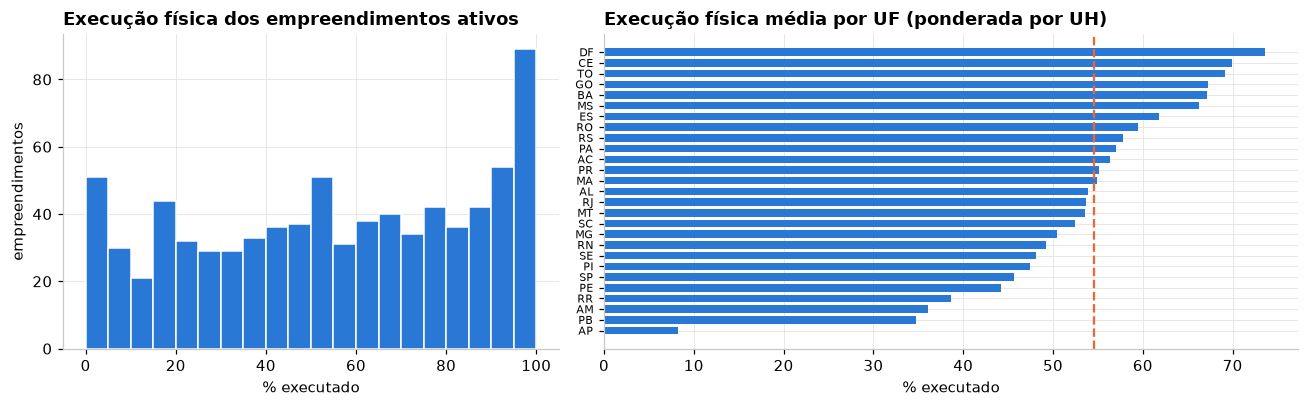

Execução física média nacional (ponderada por UH, empreendimentos ativos): 54.5%
Empreendimentos ativos com 0% de execução: 44 | acima de 90%: 143


In [19]:
# Percentual de execução física: distribuição e por UF
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 1.4]})
ex = ficha[ficha.situacao_empreendimento.isin(["EM ANDAMENTO","PARALISADO","CONCLUÍDO E ENTREGUE"])]
axes[0].hist(ex.percentual_execucao_fisica.dropna(), bins=20, range=(0, 100), color=C["azul"], edgecolor="white")
axes[0].set_title("Execução física dos empreendimentos ativos"); axes[0].set_xlabel("% executado"); axes[0].set_ylabel("empreendimentos")
ufe = ex.groupby("uf").apply(lambda d: np.average(d.percentual_execucao_fisica.fillna(0), weights=d.quantidade_uh)).sort_values()
axes[1].barh(ufe.index, ufe.values, color=C["azul"], height=0.7); axes[1].set_title("Execução física média por UF (ponderada por UH)"); axes[1].set_xlabel("% executado")
axes[1].axvline(np.average(ex.percentual_execucao_fisica.fillna(0), weights=ex.quantidade_uh), color=C["laranja"], lw=1.5, ls="--")
axes[1].tick_params(axis="y", labelsize=7)
plt.tight_layout(); plt.show()
print(f"Execução física média nacional (ponderada por UH, empreendimentos ativos): {np.average(ex.percentual_execucao_fisica.fillna(0), weights=ex.quantidade_uh):.1f}%")
print("Empreendimentos ativos com 0% de execução:", int((ex.percentual_execucao_fisica.fillna(0) == 0).sum()), "| acima de 90%:", int((ex.percentual_execucao_fisica >= 90).sum()))

### A curva S da carteira

A série mensal por APF (`ouro.ouro_far_serie_mensal_apf`) traz o físico realizado (MONIT, com complemento da CAIXA), o físico previsto pelo cronograma vigente e o financeiro (liberações acumuladas sobre o valor FAR). Primeiro a curva agregada por mês calendário, como o dashboard mostra hoje; depois a curva **por mês de obra**, que é como o secretário e o Mintsu pediram para olhar.

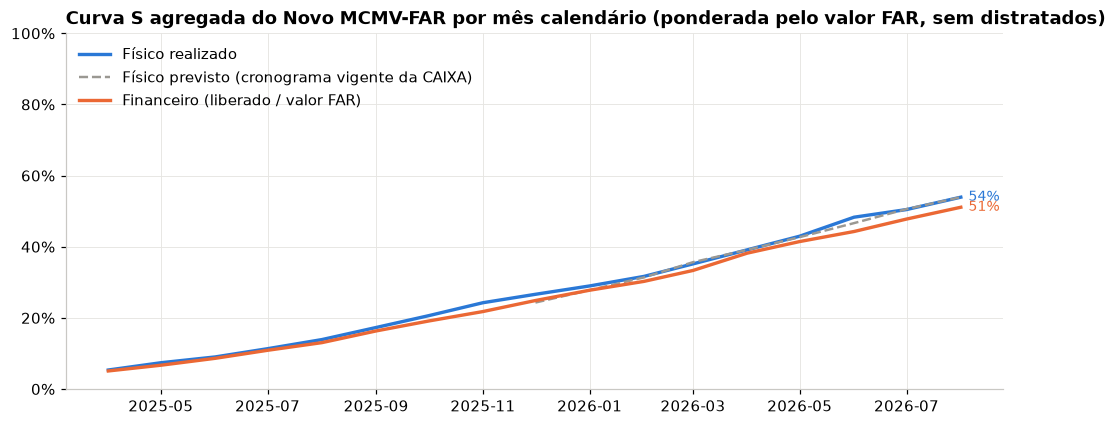

,mes_label,qt_empreendimentos,pct_obra_realizada,pct_obra_prevista,pct_financeiro,vr_liberado_acum
60,2026-03,808,35.180000,35.660000,33.330000,"R$ 6,44 bi"
61,2026-04,808,39.130000,39.130000,38.200000,"R$ 7,39 bi"
62,2026-05,808,42.970000,42.700000,41.460000,"R$ 8,02 bi"
63,2026-06,808,48.300000,46.640000,44.280000,"R$ 8,58 bi"
64,2026-07,808,50.450000,50.590000,47.780000,"R$ 9,27 bi"
65,2026-08,808,53.930000,53.940000,51.100000,"R$ 9,93 bi"


In [20]:
curva = cache("far_curva_s_nacional", "select * from ouro.ouro_far_curva_s where nivel = 'nacional' order by portaria, mes")
curva["mes"] = pd.to_datetime(curva.mes)
cn = curva[curva.portaria == "Todas as portarias"]
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(cn.mes, cn.pct_obra_realizada, color=C["azul"], lw=2.2, label="Físico realizado")
ax.plot(cn.mes, cn.pct_obra_prevista, color=C["cinza"], lw=1.6, ls="--", label="Físico previsto (cronograma vigente da CAIXA)")
ax.plot(cn.mes, cn.pct_financeiro, color=C["laranja"], lw=2.2, label="Financeiro (liberado / valor FAR)")
ax.set_ylim(0, 100); ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.legend(loc="upper left")
ax.set_title("Curva S agregada do Novo MCMV-FAR por mês calendário (ponderada pelo valor FAR, sem distratados)")
for col, cor in [("pct_obra_realizada", C["azul"]), ("pct_financeiro", C["laranja"])]:
    ax.annotate(f"{cn[col].iloc[-1]:.0f}%", (cn.mes.iloc[-1], cn[col].iloc[-1]), xytext=(5, 0), textcoords="offset points", color=cor, fontsize=9, va="center")
plt.show()
display(cn[["mes_label","qt_empreendimentos","pct_obra_realizada","pct_obra_prevista","pct_financeiro","vr_liberado_acum"]].tail(6).style.format({"vr_liberado_acum": brl}))

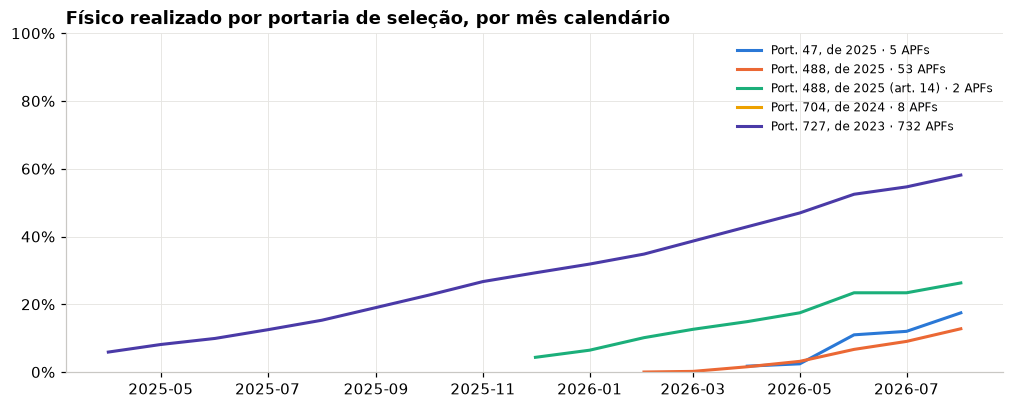

In [21]:
# Curva S por portaria (mês calendário): cada ciclo entra em momento diferente
fig, ax = plt.subplots(figsize=(11, 4))
cores = [C["azul"], C["laranja"], C["verde"], C["amarelo"], C["roxo"]]
for (p, d), cor in zip([(p, d) for p, d in curva.groupby("portaria") if p != "Todas as portarias"], cores):
    rot = p.replace("Portaria MCID nº ", "Port. ").replace(" (Art. 14, prorrogadas da 727/2023)", " (art. 14)")
    ax.plot(d.mes, d.pct_obra_realizada, lw=2, color=cor, label=f"{rot} · {int(d.qt_empreendimentos.iloc[-1])} APFs")
ax.set_ylim(0, 100); ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.legend(fontsize=8)
ax.set_title("Físico realizado por portaria de seleção, por mês calendário")
plt.show()

In [22]:
serie = cache("far_serie_mensal_apf", """
select apf, uf, mes, dt_inicio_obra, mes_inicio_fisico, etapa, pct_obra_realizada, pct_obra_prevista, desvio_fisico, fonte_fisica, situacao_obra,
       vr_liberado_mes, vr_liberado_acum, vr_emprestimo_far, pct_financeiro, situacao_caixa, pct_execucao_caixa, ritmo_fisico_financeiro
from ouro.ouro_far_serie_mensal_apf""")
serie["mes"] = pd.to_datetime(serie.mes); serie["dt_inicio_obra"] = pd.to_datetime(serie.dt_inicio_obra)
serie = serie.merge(ficha[["apf","dt_contratacao","quantidade_uh","situacao_empreendimento","portaria_selecao","portaria_final"]], on="apf", how="left")
# Mês de obra: contado da contratação (mês 0 = mês da contratação). Alternativa: do início físico.
serie["mes_contrato"] = ((serie.mes.dt.year - serie.dt_contratacao.dt.year)*12 + (serie.mes.dt.month - serie.dt_contratacao.dt.month)).astype("Int64")
serie["mes_obra"] = ((serie.mes.dt.year - serie.dt_inicio_obra.dt.year)*12 + (serie.mes.dt.month - serie.dt_inicio_obra.dt.month)).astype("Int64")
ativos = serie[~serie.situacao_empreendimento.isin(["DISTRATADO/CANCELADO"]) & serie.pct_obra_realizada.notna() & (serie.fonte_fisica != "carregado")]
print(f"{ativos.apf.nunique()} APFs com medição física observada; {len(ativos):,} pontos APF x mês".replace(",", "."))

808 APFs com medição física observada; 12.815 pontos APF x mês


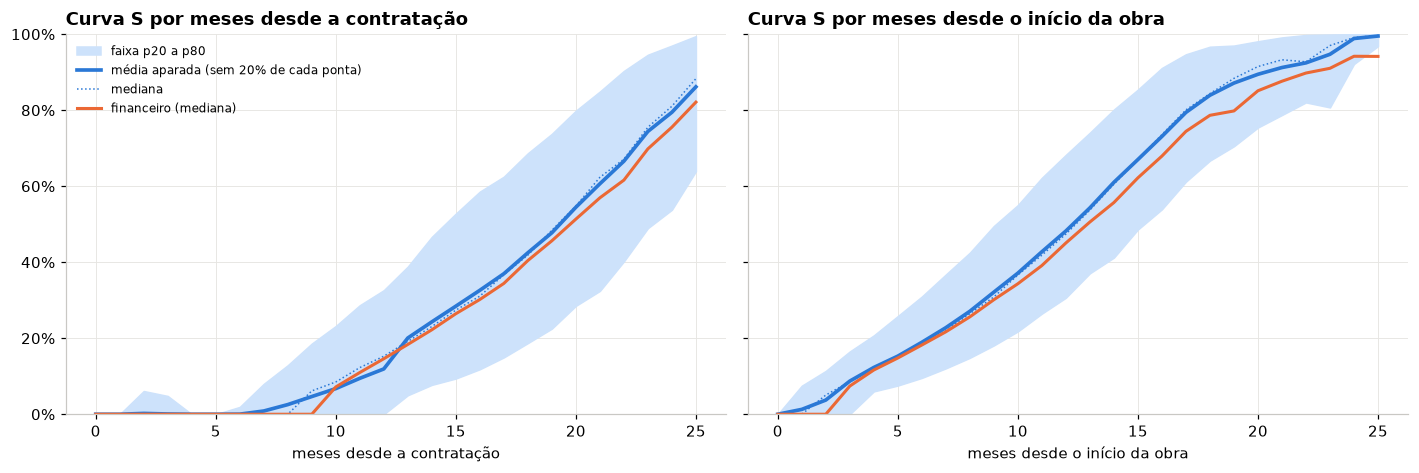

Régua por mês desde a contratação (média aparada do físico):


,n,media_aparada,mediana,p20,p80,financeiro_mediana
mes_contrato,,,,,,
3,175,0.1,0.0,0.0,4.8,0.0
6,393,0.0,0.0,0.0,1.9,0.0
9,727,4.7,6.1,0.0,18.6,0.0
12,736,11.9,15.3,0.0,32.6,14.6
15,729,28.4,27.4,9.4,52.8,26.4
18,692,42.5,41.9,18.7,68.7,40.4
21,541,60.6,62.3,32.4,84.9,56.9
24,229,79.5,81.0,53.8,97.0,75.5


In [23]:
def regua(df, eixo, col="pct_obra_realizada", min_n=15):
    g = df[df[eixo] >= 0].groupby(eixo)
    r = pd.DataFrame({"n": g[col].size(), "media": g[col].mean(), "mediana": g[col].median(),
                      "p20": g[col].quantile(0.2), "p80": g[col].quantile(0.8),
                      "media_aparada": g[col].apply(lambda s: s[(s >= s.quantile(0.2)) & (s <= s.quantile(0.8))].mean())})
    r["financeiro_mediana"] = g["pct_financeiro"].median()
    return r[r.n >= min_n]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for ax, eixo, titulo in zip(axes, ["mes_contrato", "mes_obra"], ["meses desde a contratação", "meses desde o início da obra"]):
    r = regua(ativos, eixo)
    ax.fill_between(r.index, r.p20, r.p80, color="#cde2fb", label="faixa p20 a p80")
    ax.plot(r.index, r.media_aparada, color=C["azul"], lw=2.4, label="média aparada (sem 20% de cada ponta)")
    ax.plot(r.index, r.mediana, color=C["azul"], lw=1, ls=":", label="mediana")
    ax.plot(r.index, r.financeiro_mediana, color=C["laranja"], lw=2, label="financeiro (mediana)")
    ax.set_title(f"Curva S por {titulo}"); ax.set_xlabel(titulo); ax.set_ylim(0, 100)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter())
axes[0].legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()
r = regua(ativos, "mes_contrato")
print("Régua por mês desde a contratação (média aparada do físico):")
display(r.loc[[m for m in [3, 6, 9, 12, 15, 18, 21, 24] if m in r.index], ["n","media_aparada","mediana","p20","p80","financeiro_mediana"]].round(1))

<div style="border:2px solid #d03b3b;background:#fff4f4;padding:10px 14px;border-radius:6px;margin:6px 0"><b style="color:#d03b3b">⚠ Fora do banco: parâmetros da régua</b><ul style="margin:6px 0 0 0"><li>Faixa p20 a p80, média aparada (sem 20% de cada ponta), mínimo de 15 obras por mês de contrato e a posição "abaixo / dentro / acima" são escolhas deste notebook (recomendação do Mintsu, 23/10/2026), não dados.</li><li><b>Como levar ao banco:</b> modelo <code>ouro.ouro_far_regua_mes_contrato</code> (mes_contrato, n, p20, p80, media_aparada, financeiro_mediana) e coluna <code>posicao_regua</code> na série mensal por APF, com os parâmetros declarados em <code>dbt_project.yml</code> (vars) para serem auditáveis.</li></ul></div>

**Leitura.** Deslocar as curvas para o mês de obra, como o Mintsu recomendou, muda a história: por mês calendário a carteira parece avançar devagar porque entram obras novas a cada mês; por mês de contrato a obra típica chega perto da metade entre o 12º e o 15º mês. A faixa entre o p20 e o p80 é a "régua" que vai dizer quem está normal, atrasado ou adiantado. O financeiro anda colado ao físico, o que é esperado num programa que paga por medição. O que falta aqui é a curva inteira: quase não há obra concluída no FAR novo, então a régua só descreve o começo do ciclo. O histórico pré-2024 (`prata_hist_far_empreendimento`) é o caminho para completar.

### Como o GEHIS se conecta com a curva S

O GEHIS fala de cada obra; a curva S agregada fala da carteira ponderada pelo valor. Para ligar os dois, pego a situação GEHIS de cada APF no retrato de julho de 2026 e olho a mesma obra na série mensal: físico realizado, previsto, desvio (realizado menos previsto), financeiro e meses desde a contratação. Depois desenho a curva S por mês de contrato separada por status GEHIS.

,obras,fisico,previsto,desvio,financeiro,meses_contrato,uh
gehis,,,,,,,
EM ATENCAO,385,50.5,55.0,-4.5,47.7,21.0,60250.0
NORMAL,315,58.9,53.3,5.7,55.4,19.1,45077.0
OBRA NAO INICIADA,55,1.3,1.1,0.2,1.1,12.1,8566.0
OBRA SOLUCIONADA,25,100.0,91.3,8.7,96.2,24.0,3525.0
RISCO DE PARALISACAO,4,20.7,24.4,-3.7,18.9,21.5,792.0
SEM INFORMACAO,4,100.0,65.2,34.8,94.6,21.5,252.0
TRATAMENTO CUSTOMIZADO,3,6.2,14.7,-8.5,2.8,18.0,528.0
OBRA RETOMADA,2,25.3,33.9,-8.6,24.8,24.0,77.0
PARALISADO,2,20.5,40.4,-19.9,20.6,19.0,300.0


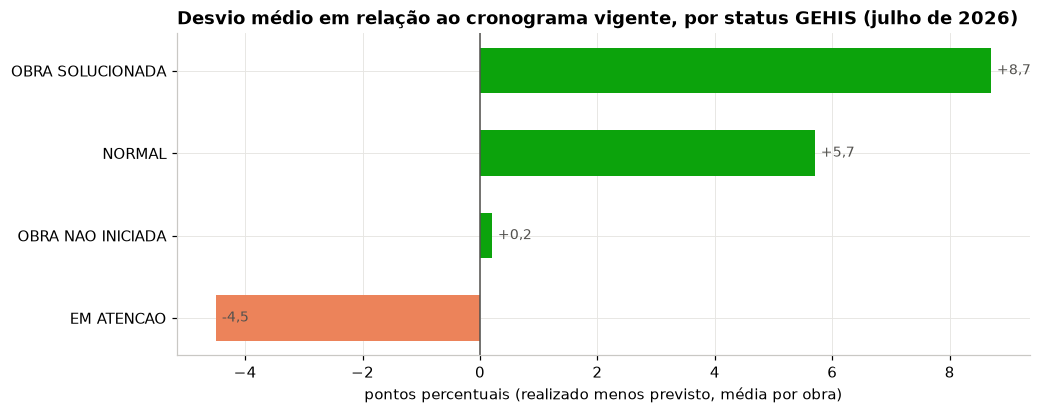

In [24]:
mes_ref = "2026-07-01"
g_jul = gehis[gehis.anomes == "202607"].drop_duplicates("apf")[["apf","situacao"]].rename(columns={"situacao": "gehis"})
s_jul = serie[serie.mes == mes_ref].merge(g_jul, on="apf", how="inner")
cmp = s_jul.groupby("gehis").agg(obras=("apf","size"), fisico=("pct_obra_realizada","mean"), previsto=("pct_obra_prevista","mean"), desvio=("desvio_fisico","mean"),
                                 financeiro=("pct_financeiro","mean"), meses_contrato=("mes_contrato","mean"), uh=("quantidade_uh","sum")).sort_values("obras", ascending=False).round(1)
display(cmp)
fig, ax = plt.subplots(figsize=(10, 3.8))
c2 = cmp[cmp.obras >= 20].sort_values("desvio")
ax.barh(c2.index, c2.desvio, color=[STATUS_C["serio"] if v < 0 else STATUS_C["bom"] for v in c2.desvio], height=0.55)
ax.axvline(0, color="#52514e", lw=1); ax.set_xlabel("pontos percentuais (realizado menos previsto, média por obra)")
ax.set_title("Desvio médio em relação ao cronograma vigente, por status GEHIS (julho de 2026)")
rotular_barras(ax, fmt=lambda v: f"{v:+.1f}".replace(".", ","), horizontal=True)
plt.show()

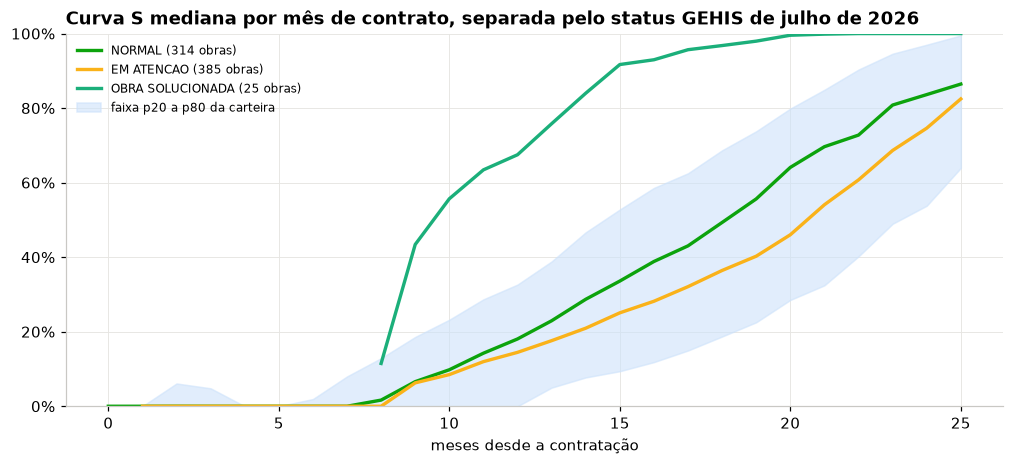

In [25]:
# Curva S por mês de contrato separada por status GEHIS (status de julho de 2026 aplicado a toda a trajetória da obra)
at = ativos.merge(g_jul, on="apf", how="inner")
fig, ax = plt.subplots(figsize=(11, 4.4))
for st, cor in [("NORMAL", STATUS_C["bom"]), ("EM ATENCAO", STATUS_C["atencao"]), ("OBRA SOLUCIONADA", C["verde"]), ("RISCO DE PARALISACAO", STATUS_C["serio"])]:
    r_st = regua(at[at.gehis == st], "mes_contrato", min_n=8)
    if len(r_st): ax.plot(r_st.index, r_st.mediana, lw=2.2, color=cor, label=f"{st} ({at[at.gehis == st].apf.nunique()} obras)")
r_all = regua(ativos, "mes_contrato")
ax.fill_between(r_all.index, r_all.p20, r_all.p80, color="#cde2fb", alpha=0.6, label="faixa p20 a p80 da carteira")
ax.set_ylim(0, 100); ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_xlabel("meses desde a contratação"); ax.legend(loc="upper left", fontsize=8)
ax.set_title("Curva S mediana por mês de contrato, separada pelo status GEHIS de julho de 2026")
plt.show()

**Leitura.** Os dois gráficos não se contradizem, eles medem coisas diferentes. A curva S agregada é ponderada pelo valor FAR e avança porque a maior parte do dinheiro está em obras que seguem medindo; o GEHIS conta obras, e quase metade delas está "em atenção". Quando se separa a curva por status, a obra "em atenção" anda, só que abaixo da faixa típica e abaixo do próprio cronograma (desvio médio de −4,6 pontos), enquanto a "normal" anda acima. Então "em atenção" significa, nos dados, uma obra com ritmo abaixo do esperado que ainda não parou: é o alerta que o secretário chamou de "atenção especial", e é a classe que a régua estatística precisa reproduzir. O que a curva agregada esconde é a dispersão: por isso a leitura por obra (régua, lista de atenção) tem de acompanhar a leitura da carteira.

### Curva S por portaria, por mês de contrato

Com a `portaria_final` (os 84 sem portaria atribuídos pela data), cada ciclo ganha a sua curva por mês de contrato. A 727/2023 é a única com história longa; a 488/2025 tem poucos meses e serve para ver se o novo ciclo parte no mesmo ritmo.

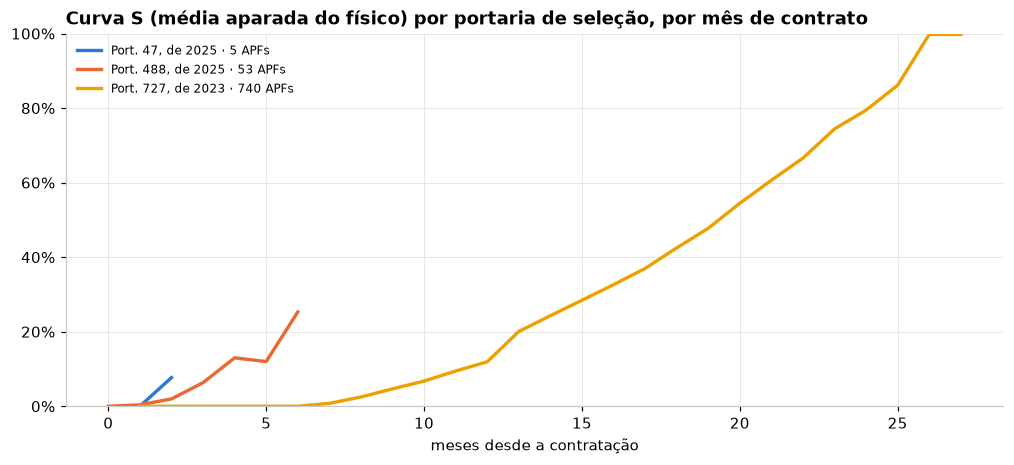

Físico médio aparado no 6º, 12º, 18º e 24º mês de contrato, por portaria:


,"Port. 47, de 2025","Port. 488, de 2025","Port. 488, de 2025 (art. 14)","Port. 727, de 2023"
mes_contrato,,,,
6,NaN,25.3,NaN,0.0
12,NaN,NaN,NaN,11.9
18,NaN,NaN,NaN,42.5
24,NaN,NaN,NaN,79.5


In [26]:
sp = serie.merge(ficha[["apf","portaria_final_curta"]], on="apf", how="left")
sp_at = sp[~sp.situacao_empreendimento.isin(["DISTRATADO/CANCELADO"]) & sp.pct_obra_realizada.notna() & (sp.fonte_fisica != "carregado")]
fig, ax = plt.subplots(figsize=(11, 4.4))
cores = [C["azul"], C["laranja"], C["verde"], C["amarelo"], C["roxo"]]
for (p, d), cor in zip(sp_at.groupby("portaria_final_curta"), cores):
    r_p = regua(d, "mes_contrato", min_n=5)
    if len(r_p):
        ax.plot(r_p.index, r_p.media_aparada, lw=2.2, color=cor, label=f"{p} · {d.apf.nunique()} APFs")
ax.set_ylim(0, 100); ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_xlabel("meses desde a contratação"); ax.legend(fontsize=8)
ax.set_title("Curva S (média aparada do físico) por portaria de seleção, por mês de contrato")
plt.show()
tab_p = {p: regua(d, "mes_contrato", min_n=5).media_aparada.reindex([6, 12, 18, 24]).round(1) for p, d in sp_at.groupby("portaria_final_curta")}
print("Físico médio aparado no 6º, 12º, 18º e 24º mês de contrato, por portaria:"); display(pd.DataFrame(tab_p))

,empreendimentos,uh,valor_far
posicao,,,
abaixo da faixa (atrasado),190,29.355,"R$ 4,66 bi"
acima da faixa (adiantado),125,17.280,"R$ 2,74 bi"
dentro da faixa,472,71.723,"R$ 11,42 bi"


situacao_caixa
posicao


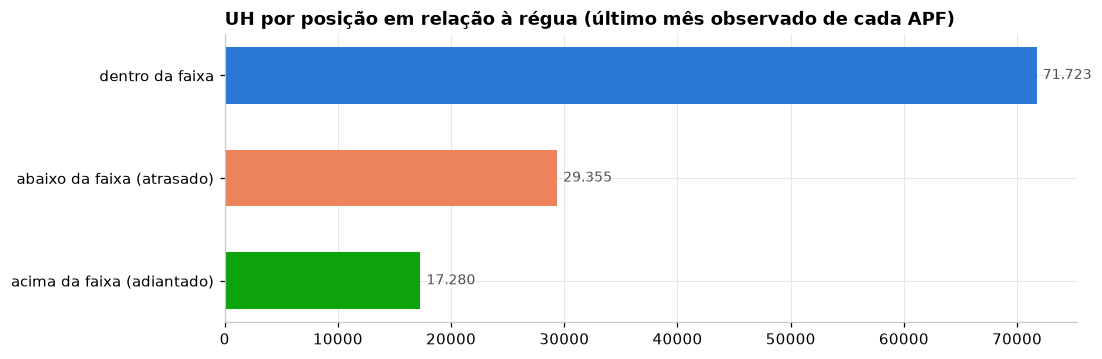

In [27]:
# Quem está fora da faixa hoje: APFs abaixo do p20 da régua no último mês observado
ult = ativos.sort_values("mes").groupby("apf").tail(1).merge(r[["p20","p80","media_aparada"]], left_on="mes_contrato", right_index=True, how="inner")
ult["posicao"] = np.select([ult.pct_obra_realizada < ult.p20, ult.pct_obra_realizada > ult.p80], ["abaixo da faixa (atrasado)", "acima da faixa (adiantado)"], "dentro da faixa")
res = ult.groupby("posicao").agg(empreendimentos=("apf","size"), uh=("quantidade_uh","sum"), valor_far=("vr_emprestimo_far","sum"))
display(res.style.format({"valor_far": brl, "uh": num}))
cruz = pd.crosstab(ult.posicao, ult.situacao_caixa)
display(cruz)
fig, ax = plt.subplots(figsize=(10, 3.4))
s = res.uh.sort_values()
ax.barh(s.index, s.values, color=[STATUS["serio"] if "atrasado" in i else (STATUS["bom"] if "adiantado" in i else C["azul"]) for i in s.index], height=0.55)
ax.set_title("UH por posição em relação à régua (último mês observado de cada APF)"); rotular_barras(ax, horizontal=True)
plt.show()

## 5. Desembolso: o dinheiro que saiu do FAR

O desembolso é por medição, direto ao credor, e o ciclo se repete a cada medição. O livro-razão do MONIT (`prata.prata_far_financeiro_mensal`) registra cada liberação com a sua composição (obra, terreno, INCC, trabalho social, legalização, aporte).

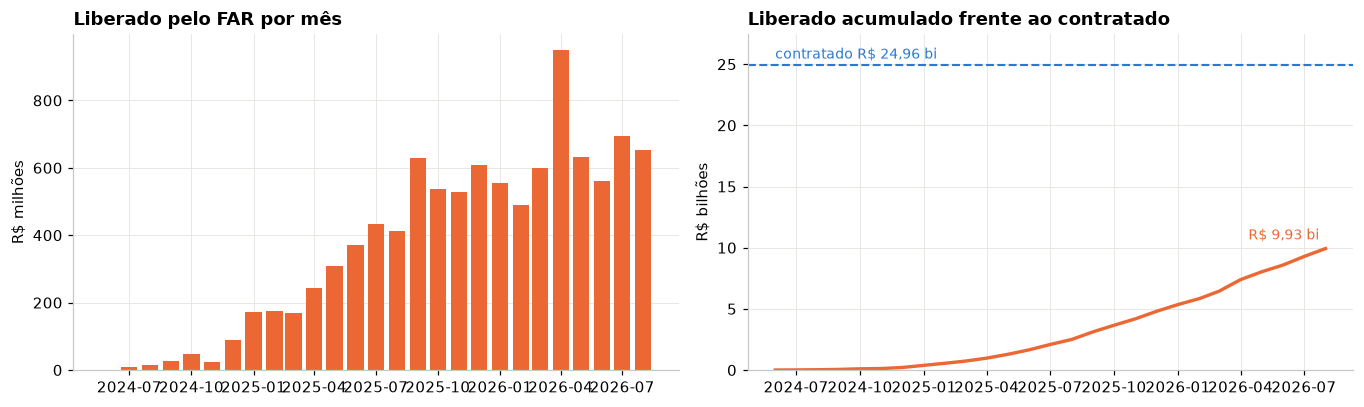

Total liberado: R$ 9,93 bi em 12.469 liberações para 767 APFs
Primeira liberação: 13/06/2024  |  média dos últimos 6 meses: R$ 680,70 mi por mês


In [28]:
fin = cache("far_financeiro", """
select apf, dt_liberacao, co_tipo_lib_recurso, vr_liberado, vr_pago_obra, vr_pago_terreno, vr_pago_trabalho_social, vr_pago_equipamentos,
       vr_pago_aporte, vr_pago_manutencao, vr_pago_incc, vr_pago_legalizacao
from prata.prata_far_financeiro_mensal""")
fin["dt_liberacao"] = pd.to_datetime(fin.dt_liberacao)
fm = fin.set_index("dt_liberacao").resample("MS").agg(liberacoes=("apf","size"), liberado=("vr_liberado","sum"))
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8))
axes[0].bar(fm.index, fm.liberado/1e6, width=24, color=C["laranja"]); axes[0].set_title("Liberado pelo FAR por mês"); axes[0].set_ylabel("R$ milhões")
axes[1].plot(fm.index, fm.liberado.cumsum()/1e9, color=C["laranja"], lw=2.2, label="liberado acumulado")
axes[1].axhline(tot["contratado"]/1e9, color=C["azul"], lw=1.4, ls="--"); axes[1].annotate(f"contratado {brl(tot['contratado'])}", (fm.index[0], tot["contratado"]/1e9), xytext=(0, 4), textcoords="offset points", fontsize=9, color=C["azul"])
axes[1].set_title("Liberado acumulado frente ao contratado"); axes[1].set_ylabel("R$ bilhões"); axes[1].set_ylim(0, tot["contratado"]/1e9*1.1)
axes[1].annotate(brl(fm.liberado.sum()), (fm.index[-1], fm.liberado.sum()/1e9), xytext=(-4, 6), textcoords="offset points", ha="right", fontsize=9, color=C["laranja"])
plt.tight_layout(); plt.show()
print(f"Total liberado: {brl(fin.vr_liberado.sum())} em {num(len(fin))} liberações para {fin.apf.nunique()} APFs")
print(f"Primeira liberação: {fin.dt_liberacao.min():%d/%m/%Y}  |  média dos últimos 6 meses: {brl(fm.liberado.tail(6).mean())} por mês")

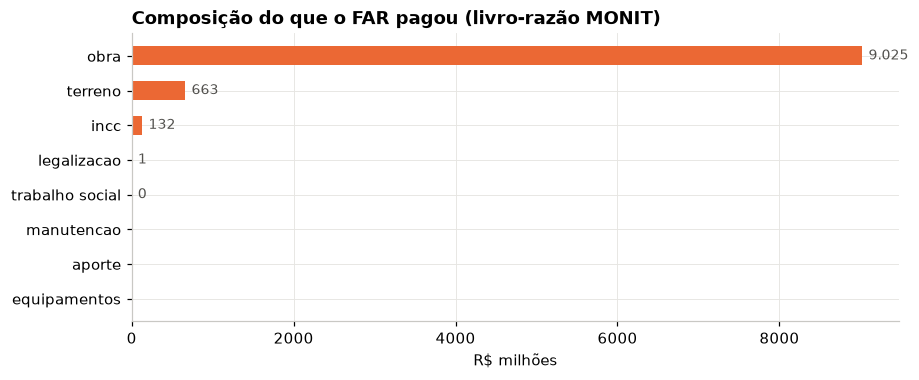

Parcela paga como INCC (correção) sobre o total: 1.3%


In [29]:
# Para onde vai o dinheiro: composição das liberações
comp = fin[["vr_pago_obra","vr_pago_terreno","vr_pago_incc","vr_pago_trabalho_social","vr_pago_equipamentos","vr_pago_aporte","vr_pago_legalizacao","vr_pago_manutencao"]].sum().sort_values()
comp.index = [i.replace("vr_pago_", "").replace("_", " ") for i in comp.index]
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.barh(comp.index, comp.values/1e6, color=C["laranja"], height=0.55); ax.set_xlabel("R$ milhões"); ax.set_title("Composição do que o FAR pagou (livro-razão MONIT)")
rotular_barras(ax, fmt=lambda v: f"{v:,.0f}".replace(",", "."), horizontal=True)
plt.show()
print("Parcela paga como INCC (correção) sobre o total:", f"{100*comp['incc']/comp.sum():.1f}%")

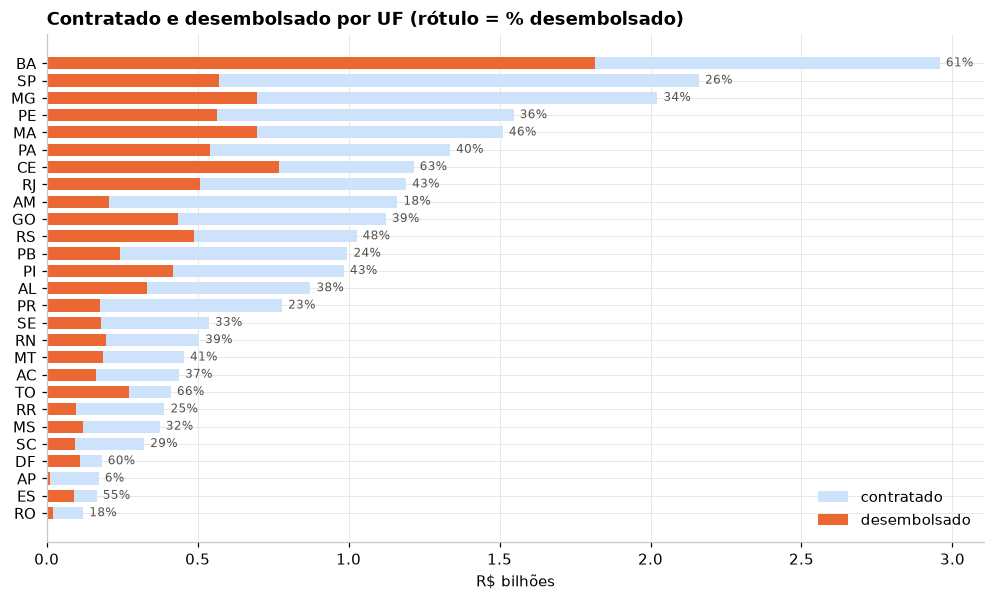

In [30]:
# Desembolso frente ao contratado por UF: onde o dinheiro já saiu e onde ainda está por sair
uf["pct_desemb"] = 100*uf.desembolsado/uf.contratado
u = uf.sort_values("contratado")
fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(u.index, u.contratado/1e9, color="#cde2fb", height=0.7, label="contratado")
ax.barh(u.index, u.desembolsado/1e9, color=C["laranja"], height=0.7, label="desembolsado")
for i, (idx, row) in enumerate(u.iterrows()):
    ax.annotate(f"{row.pct_desemb:.0f}%", (row.contratado/1e9, i), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8, color="#52514e")
ax.set_xlabel("R$ bilhões"); ax.set_title("Contratado e desembolsado por UF (rótulo = % desembolsado)"); ax.legend(loc="lower right")
plt.show()

## 6. Entrega: o que chegou às famílias

O fim do fluxo é a conclusão com habite-se, a designação da UH e o contrato com as famílias. O retrato mensal da CAIXA (`prata.prata_far_caixa_serie`) traz UH entregues por competência; a ficha traz as datas de previsão de entrega.

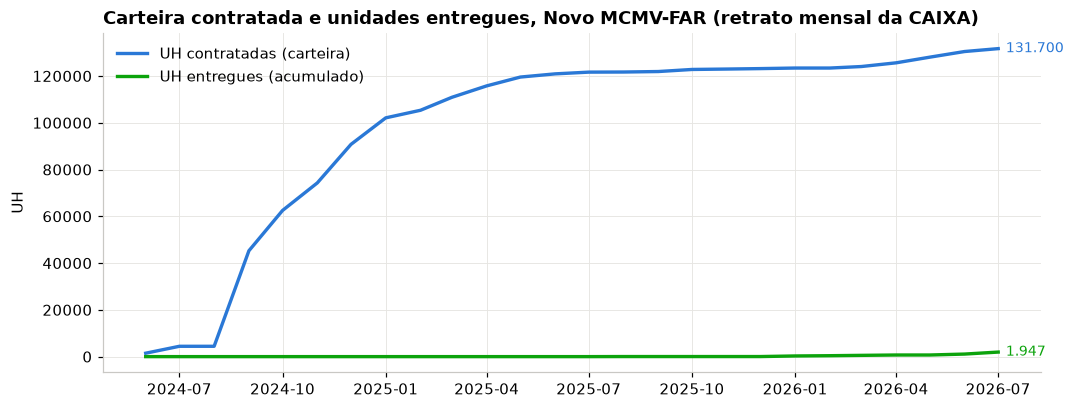

Em 07/2026: 1.947 UH entregues de 131.700 contratadas (1.5%)
Primeira entrega registrada: 08/2025


In [31]:
cx = cache("far_caixa_serie", """
select apf, competencia, situacao, pct_execucao, valor_desembolsado, uh_contratadas, uh_entregues
from prata.prata_far_caixa_serie where apf in (select apf from ouro.ouro_far_ficha_empreendimento)""")
cx["competencia"] = pd.to_datetime(cx.competencia)
ent = cx.groupby("competencia").agg(apfs=("apf","nunique"), uh_contratadas=("uh_contratadas","sum"), uh_entregues=("uh_entregues","sum"))
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(ent.index, ent.uh_contratadas, color=C["azul"], lw=2.2, label="UH contratadas (carteira)")
ax.plot(ent.index, ent.uh_entregues, color=STATUS["bom"], lw=2.2, label="UH entregues (acumulado)")
ax.legend(loc="upper left"); ax.set_title("Carteira contratada e unidades entregues, Novo MCMV-FAR (retrato mensal da CAIXA)"); ax.set_ylabel("UH")
ax.annotate(num(ent.uh_entregues.iloc[-1]), (ent.index[-1], ent.uh_entregues.iloc[-1]), xytext=(5, 0), textcoords="offset points", color=STATUS["bom"], fontsize=9, va="center")
ax.annotate(num(ent.uh_contratadas.iloc[-1]), (ent.index[-1], ent.uh_contratadas.iloc[-1]), xytext=(5, 0), textcoords="offset points", color=C["azul"], fontsize=9, va="center")
plt.show()
u_ent = ent.uh_entregues.iloc[-1]; u_con = ent.uh_contratadas.iloc[-1]
print(f"Em {ent.index[-1]:%m/%Y}: {num(u_ent)} UH entregues de {num(u_con)} contratadas ({100*u_ent/u_con:.1f}%)")
print("Primeira entrega registrada:", f"{ent[ent.uh_entregues > 0].index.min():%m/%Y}")

### Quais empreendimentos já deveriam ter sido entregues, e por que não foram

Há três previsões diferentes na base. A **previsão original de conclusão da obra** (`dt_previsao_conclusao` do cadastro PJ do MONIT) existe para os 878 APFs e é a promessa feita na contratação. A **previsão de entrega** da obra mensal do MONIT (`dt_previsao_entrega`) é, na prática, a previsão de conclusão mais um trimestre (o gráfico do calendário mostra as duas séries deslocadas em exatamente um trimestre), não uma reprogramação. E a **previsão de entrega dos Dados Prioritários** (`dt_previsao_entrega` da ficha) só é preenchida perto do fim, em 53 APFs. Para a pergunta "quem já deveria ter sido entregue", uso a promessa original e comparo com a situação de hoje.

In [32]:
obra = cache("far_obra_mensal", """
select apf, co_situacao_obra, dt_alteracao_situacao, pct_obra_prevista, pct_obra_realizada, dt_paralisacao, co_classificacao_paralisado, co_motivo_cancelamento,
       dt_previsao_entrega as dt_previsao_entrega_monit, dt_conclusao_obra as dt_conclusao_obra_monit, dt_entrega as dt_entrega_monit, dt_repactuacao, dt_legalizacao,
       qt_uh_sem_habitese, qt_uh_invadidas, ic_invadido, providencias_invasao
from prata.prata_far_obra_mensal""")
for c in ["dt_alteracao_situacao","dt_paralisacao","dt_previsao_entrega_monit","dt_conclusao_obra_monit","dt_entrega_monit","dt_repactuacao","dt_legalizacao"]:
    obra[c] = pd.to_datetime(obra[c])
SIT_MONIT = cache("seed_far_situacao_obra", "select co_situacao_obra, situacao_obra from seeds.far_situacao_obra").astype({"co_situacao_obra": int}).set_index("co_situacao_obra").situacao_obra.to_dict()  # dicionário vem da seed do banco
obra["situacao_monit"] = obra.co_situacao_obra.map(SIT_MONIT)
hoje = pd.Timestamp("2026-08-31")
ent = ficha.merge(obra, on="apf", how="left").merge(g_jul, on="apf", how="left")
ent["gehis"] = ent.gehis.fillna("fora do GEHIS")
ent["atraso_meses"] = ((hoje - ent.dt_previsao_conclusao).dt.days / 30.44).round(1)
ent["ult_liberacao"] = ent.apf.map(fin.groupby("apf").dt_liberacao.max())
ent["meses_sem_liberacao"] = ((hoje - ent.ult_liberacao).dt.days / 30.44).round(1)
venc = ent[(ent.dt_previsao_conclusao < hoje)].copy()
print(f"Promessa original de conclusão já vencida: {len(venc)} empreendimentos, {num(venc.quantidade_uh.sum())} UH, {brl(venc.valor_contratado.sum())}")
display(venc.groupby("situacao_empreendimento").agg(empreendimentos=("apf","size"), uh=("quantidade_uh","sum"), exec_media=("percentual_execucao_fisica","mean"), atraso_medio_meses=("atraso_meses","mean")).round(1))
pend = venc[venc.situacao_empreendimento.isin(["EM ANDAMENTO","PARALISADO"])].copy()
print(f"\nAinda em obra com a promessa vencida: {len(pend)} empreendimentos, {num(pend.quantidade_uh.sum())} UH")
display(pd.crosstab(pend.gehis, pend.situacao_monit, margins=True))

Promessa original de conclusão já vencida: 140 empreendimentos, 19.592 UH, R$ 3,50 bi


,empreendimentos,uh,exec_media,atraso_medio_meses
situacao_empreendimento,,,,
CONCLUÍDO E ENTREGUE,12,1546,99.8,3.8
DISTRATADO/CANCELADO,71,10806,0.0,3.8
EM ANDAMENTO,57,7240,81.9,2.0



Ainda em obra com a promessa vencida: 57 empreendimentos, 7.240 UH


situacao_monit,ATRASADA,CONCLUÍDA,EM ANDAMENTO,NORMAL,NÃO INICIADA,All
gehis,,,,,,
EM ATENCAO,4,4,3,8,0,19
NORMAL,2,2,7,10,2,23
OBRA NAO INICIADA,0,0,0,0,6,6
OBRA SOLUCIONADA,0,9,0,0,0,9
All,6,15,10,18,8,57


,empreendimentos,uh,exec_media,atraso_medio_meses
motivo_dado,,,,
"em andamento, só atraso de cronograma",27,3562,65.5,1.9
em atenção: ritmo abaixo do cronograma,15,1738,93.5,1.3
"obra pronta, falta habite-se, legalização ou designação",15,1940,100.0,3.0


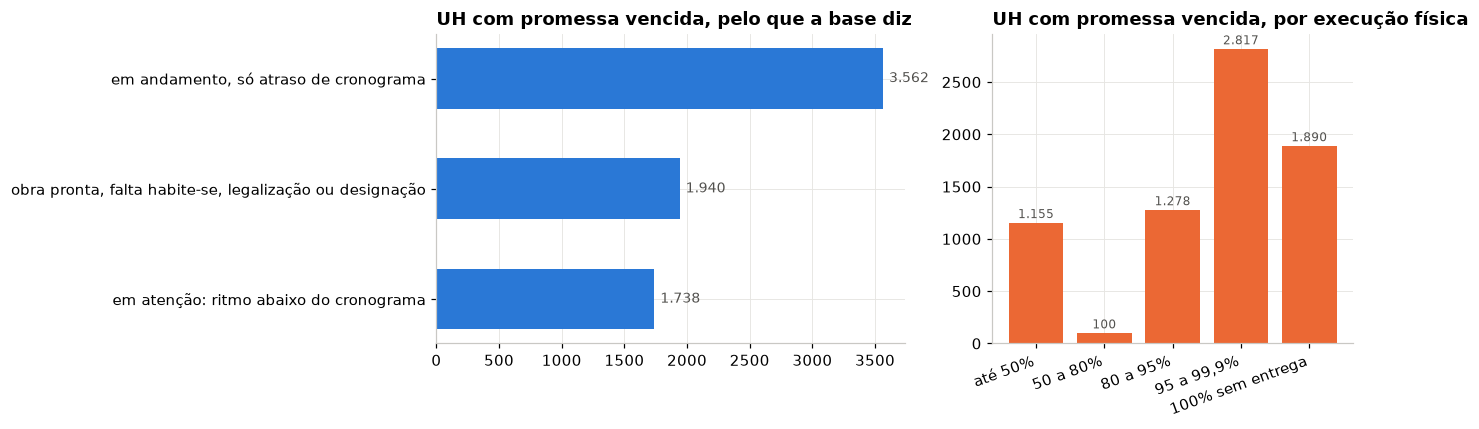

As 20 obras mais atrasadas em relação à promessa original:


,apf,nome_empreendimento,municipio_uf,portaria_final_curta,quantidade_uh,dt_contratacao,dt_previsao_conclusao,atraso_meses,percentual_execucao_fisica,situacao_empreendimento,situacao_monit,gehis,meses_sem_liberacao,motivo_dado
10,62663083,RESIDENCIAL VILA FLORIDA V,Matão/SP,"Port. 727, de 2023",90,29/05/2024,12/12/2025,8.600000,100.0%,EM ANDAMENTO,CONCLUÍDA,OBRA SOLUCIONADA,nan,"obra pronta, falta habite-se, legalização ou designação"
616,63396684,CONJUNTO HABITACIONAL MANERA,Mogi Mirim/SP,"Port. 727, de 2023",100,26/07/2024,05/02/2026,6.800000,0.0%,EM ANDAMENTO,NÃO INICIADA,OBRA NAO INICIADA,nan,"em andamento, só atraso de cronograma"
53,62743758,VERDES HORIZONTES I,Camaçari/BA,"Port. 727, de 2023",192,19/07/2024,28/02/2026,6.000000,100.0%,EM ANDAMENTO,CONCLUÍDA,OBRA SOLUCIONADA,nan,"obra pronta, falta habite-se, legalização ou designação"
559,63308636,MORAR MELHOR XXII,Manaus/AM,"Port. 727, de 2023",160,24/09/2024,15/03/2026,5.600000,0.0%,EM ANDAMENTO,NÃO INICIADA,OBRA NAO INICIADA,nan,"em andamento, só atraso de cronograma"
561,63308855,MORAR MELHOR XXIII,Manaus/AM,"Port. 727, de 2023",160,24/09/2024,15/03/2026,5.600000,0.0%,EM ANDAMENTO,NÃO INICIADA,OBRA NAO INICIADA,nan,"em andamento, só atraso de cronograma"
252,63135226,RESIDENCIAL JARDIM PORTO FRANCO I,Porto Franco/MA,"Port. 727, de 2023",50,02/07/2024,01/04/2026,5.000000,100.0%,EM ANDAMENTO,CONCLUÍDA,OBRA SOLUCIONADA,nan,"obra pronta, falta habite-se, legalização ou designação"
178,63050651,CAMOCIM I,Camocim/CE,"Port. 727, de 2023",150,02/08/2024,09/04/2026,4.700000,96.5%,EM ANDAMENTO,NORMAL,EM ATENCAO,nan,em atenção: ritmo abaixo do cronograma
12,62689251,RESIDENCIAL VIVENDAS PANORAMA I,Feira de Santana/BA,"Port. 727, de 2023",200,28/06/2024,17/04/2026,4.500000,100.0%,EM ANDAMENTO,CONCLUÍDA,EM ATENCAO,nan,"obra pronta, falta habite-se, legalização ou designação"
709,63723858,MORAR MELHOR XXI,Manaus/AM,"Port. 727, de 2023",160,17/09/2024,15/04/2026,4.500000,0.0%,EM ANDAMENTO,NÃO INICIADA,OBRA NAO INICIADA,nan,"em andamento, só atraso de cronograma"
13,62689365,RESIDENCIAL VIVENDAS PANORAMA II,Feira de Santana/BA,"Port. 727, de 2023",200,28/06/2024,17/04/2026,4.500000,100.0%,EM ANDAMENTO,CONCLUÍDA,EM ATENCAO,nan,"obra pronta, falta habite-se, legalização ou designação"


Lista completa em output/far_obras_promessa_vencida.csv


In [33]:
# Por que não foram entregues: o que a base consegue dizer
pend["faixa_exec"] = pd.cut(pend.percentual_execucao_fisica.fillna(0), [-1, 50, 80, 95, 99.99, 100], labels=["até 50%", "50 a 80%", "80 a 95%", "95 a 99,9%", "100% sem entrega"])
pend["motivo_dado"] = np.select(
    [pend.situacao_empreendimento == "PARALISADO", pend.gehis.isin(["PARALISADO","RISCO DE PARALISACAO"]), pend.percentual_execucao_fisica >= 99.99, pend.meses_sem_liberacao >= 3, pend.gehis == "EM ATENCAO"],
    ["paralisada (CAIXA)", "paralisada ou em risco (GEHIS)", "obra pronta, falta habite-se, legalização ou designação", "sem liberação há 3+ meses (regra dos 90 dias)", "em atenção: ritmo abaixo do cronograma"],
    "em andamento, só atraso de cronograma")
res = pend.groupby("motivo_dado").agg(empreendimentos=("apf","size"), uh=("quantidade_uh","sum"), exec_media=("percentual_execucao_fisica","mean"), atraso_medio_meses=("atraso_meses","mean")).sort_values("empreendimentos", ascending=False).round(1)
display(res)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4), gridspec_kw={"width_ratios": [1.3, 1]})
s = res.uh.sort_values()
axes[0].barh(s.index, s.values, color=C["azul"], height=0.55); axes[0].set_title("UH com promessa vencida, pelo que a base diz"); rotular_barras(axes[0], horizontal=True)
fx = pend.groupby("faixa_exec", observed=True).quantidade_uh.sum()
axes[1].bar(fx.index.astype(str), fx.values, color=C["laranja"]); axes[1].set_title("UH com promessa vencida, por execução física"); rotular_barras(axes[1], fontsize=8)
plt.setp(axes[1].get_xticklabels(), rotation=20, ha="right")
plt.tight_layout(); plt.show()
cols = ["apf","nome_empreendimento","municipio_uf","portaria_final_curta","quantidade_uh","dt_contratacao","dt_previsao_conclusao","atraso_meses","percentual_execucao_fisica","situacao_empreendimento","situacao_monit","gehis","meses_sem_liberacao","motivo_dado"]
print("As 20 obras mais atrasadas em relação à promessa original:")
display(pend.sort_values("atraso_meses", ascending=False)[cols].head(20).style.format({"dt_contratacao": "{:%d/%m/%Y}", "dt_previsao_conclusao": "{:%d/%m/%Y}", "percentual_execucao_fisica": "{:.1f}%"}))
pend.sort_values("atraso_meses", ascending=False)[cols].to_csv(OUT / "far_obras_promessa_vencida.csv", index=False)
print("Lista completa em output/far_obras_promessa_vencida.csv")

<div style="border:2px solid #d03b3b;background:#fff4f4;padding:10px 14px;border-radius:6px;margin:6px 0"><b style="color:#d03b3b">⚠ Fora do banco: a classificação "pelo que a base diz" e a data de hoje</b><ul style="margin:6px 0 0 0"><li>A data de referência (31/08/2026) está fixada no código; as regras de "3 meses sem liberação", "99,99% = obra pronta" e a ordem de prioridade entre os status são deste notebook.</li><li>A base não tem motivo de atraso: os campos do MONIT (<code>dt_paralisacao</code>, <code>co_classificacao_paralisado</code>, <code>co_motivo_cancelamento</code>, repactuação, invasão) vêm vazios para os 878 APFs.</li><li><b>Como levar ao banco:</b> a data de posição deve vir de <code>max(mes)</code> da série (já é assim na carga) e as regras viram um modelo ouro <code>ouro_far_obra_pendente</code> documentado; o motivo em si só entra com a "gestão do trabalho" da ficha do empreendimento (registro de ações, datas e atores pelos departamentos), pedido do secretário.</li></ul></div>

**Leitura.** A base diz *quais* obras passaram da promessa e *em que estado* estão (paralisada, em risco, em atenção, pronta sem entrega, sem liberação há meses), mas não diz *o motivo*: os campos do MONIT feitos para isso (data e classificação da paralisação, motivo do cancelamento, repactuação, invasão) vêm vazios para todos os 878 APFs, e o GEHIS traz o status sem justificativa. Os motivos reais (alvará, legalização, habite-se, substituição de construtora, pendência do ente) ficam nos ofícios e nas planilhas de acompanhamento dos departamentos, que é a "gestão do trabalho" que o secretário pediu para entrar na ficha do empreendimento. Boa parte das obras com promessa vencida está acima de 95% de execução: o atraso ali é de entrega (habite-se, designação das famílias, ligação de água e luz), não de obra.

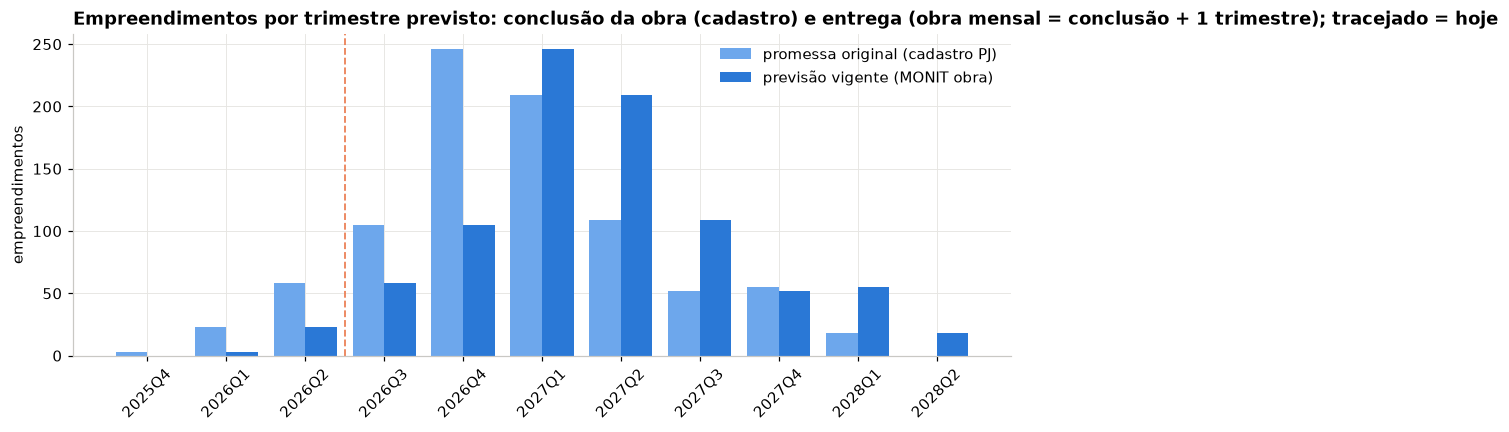

Previsão vigente do MONIT a partir de set/2026: 814 empreendimentos; já vencida: 64


In [34]:
# O calendário das promessas: quando as obras deveriam ficar prontas (promessa original) e quando a CAIXA prevê hoje (obra mensal)
cal = pd.DataFrame({
    "promessa original (cadastro PJ)": ficha.set_index("apf").dt_previsao_conclusao.dt.to_period("Q").value_counts().sort_index(),
    "previsão vigente (MONIT obra)": obra.set_index("apf").dt_previsao_entrega_monit.dt.to_period("Q").value_counts().sort_index(),
}).fillna(0)
cal = cal[(cal.index >= pd.Period("2025Q4")) & (cal.index <= pd.Period("2028Q2"))]
fig, ax = plt.subplots(figsize=(11, 3.8))
x = np.arange(len(cal)); w = 0.4
ax.bar(x - w/2, cal.iloc[:, 0], w, color=SEQ[2], label=cal.columns[0]); ax.bar(x + w/2, cal.iloc[:, 1], w, color=C["azul"], label=cal.columns[1])
ax.set_xticks(x); ax.set_xticklabels(cal.index.astype(str), rotation=45); ax.set_ylabel("empreendimentos"); ax.legend()
ax.axvline(list(cal.index.astype(str)).index("2026Q3") - 0.5, color=STATUS_C["serio"], lw=1.2, ls="--")
ax.set_title("Empreendimentos por trimestre previsto: conclusão da obra (cadastro) e entrega (obra mensal = conclusão + 1 trimestre); tracejado = hoje")
plt.show()
print(f"Previsão vigente do MONIT a partir de set/2026: {num((obra.dt_previsao_entrega_monit >= hoje).sum())} empreendimentos; já vencida: {num((obra.dt_previsao_entrega_monit < hoje).sum())}")

## 7. Famílias e pós-ocupação

Depois das chaves, o mapa termina em pós-ocupação (a família paga prestações ou é isenta) e no trabalho social. O Gov Hub tem a base de contratos pessoa física (`ouro.ouro_far_beneficiario_municipio`), que separa o legado (2009 a 2023) do Novo MCMV. Como as entregas do FAR novo começaram em 2025, a maior parte dos contratos ativos ainda é do legado. Não há nenhuma base de pós-ocupação ou de trabalho social estruturada: o secretário chamou isso de "quase outro mundo de informações" e pediu para inaugurar o módulo com o DPSM.

,municipios,contratos,ativos,inadimplentes,liquidados,distratados,retomados,pct_inadimplencia_ativos
geracao,,,,,,,,
Legado (2009–2023),857,1.172.503,131.650,34.713,887.417,5.245,0,26.4%
Novo MCMV,18,2.603,1.237,12,1.366,0,0,1.0%


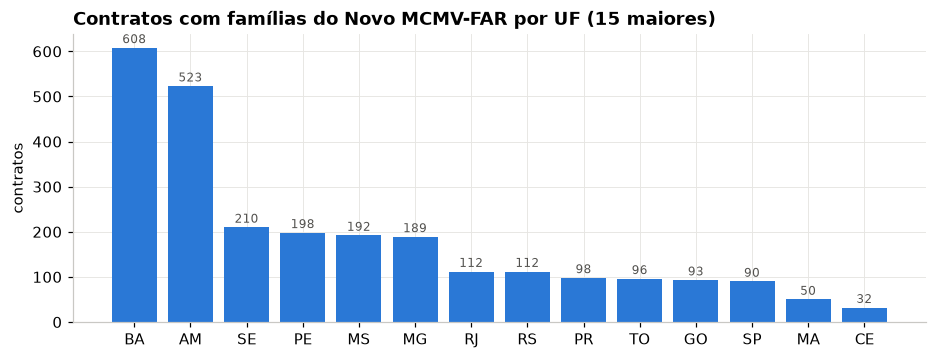

Renda média familiar (Novo MCMV-FAR, média dos municípios): R$ 1,26 mil | responsável mulher: 95%


In [35]:
ben = cache("far_beneficiario_municipio", "select * from ouro.ouro_far_beneficiario_municipio")
bg = ben.groupby("geracao").agg(municipios=("cod_ibge","nunique"), contratos=("qt_contratos","sum"), ativos=("qt_ativos","sum"), inadimplentes=("qt_inadimplentes","sum"), liquidados=("qt_liquidados","sum"), distratados=("qt_distratados","sum"), retomados=("qt_retomados","sum"))
bg["pct_inadimplencia_ativos"] = 100*bg.inadimplentes/bg.ativos
display(bg.style.format({c: num for c in ["municipios","contratos","ativos","inadimplentes","liquidados","distratados","retomados"]} | {"pct_inadimplencia_ativos": "{:.1f}%"}))
novo = ben[ben.geracao.str.contains("Novo", case=False)]
if len(novo):
    fig, ax = plt.subplots(figsize=(10, 3.4))
    s = novo.groupby("uf").qt_contratos.sum().sort_values(ascending=False).head(15)
    ax.bar(s.index, s.values, color=C["azul"]); ax.set_title("Contratos com famílias do Novo MCMV-FAR por UF (15 maiores)"); ax.set_ylabel("contratos")
    rotular_barras(ax, fontsize=8); plt.show()
    print("Renda média familiar (Novo MCMV-FAR, média dos municípios):", brl(novo.renda_media.mean()), "| responsável mulher:", f"{novo.pct_responsavel_mulher.mean():.0f}%")

## 8. Síntese: o fluxo da política e o que os dados respondem

| Etapa do mapa | Indicador | O que os dados dizem (ago/2026) | Fonte | Lacuna |
|---|---|---|---|---|
| Orçamento (00AF) | dotação, pago por exercício | 2024: R$ 7,8 bi pagos; 2025: LOA R$ 9,25 bi, pago R$ 6,7 bi; 2026: LOA R$ 5,8 bi | prata SIAFI (2025), dados abertos (2024), LOAs | saldo do FAR na CAIXA; extração anual do Tesouro Gerencial |
| Seleção | funil por fase, etapa e status (dicionário do MNPO) | 13 mil propostas, a maior parte na etapa 1; só 744 contratadas | consolidado GFAR | códigos 13 a 22 do status não documentados no MNPO 2023 |
| Contratação | APFs, UH, valor, portaria imputada pela data | R$ 25 bi e 132 mil UH; os 84 sem portaria são da 727/2023 | ficha + cadastro PJ | contrapartidas pactuadas só parciais |
| Execução | situação CAIXA, GEHIS com distrato, curva S por status e por portaria | carteira ativa de cerca de 790 obras; "em atenção" anda 4,6 pontos abaixo do cronograma | MONIT, GEHIS, Dados Prioritários | motivo do status não vem; previsto da CAIXA é reprogramado |
| Desembolso | liberado por mês, composição, por UF | 40% do contratado já saiu | livro-razão MONIT | sem cronograma financeiro previsto |
| Entrega | promessa original x hoje, previsão vigente | obras com promessa vencida listadas com o estado de cada uma | cadastro PJ, obra mensal, GEHIS | campos de motivo do MONIT vazios; gestão do trabalho fora da base |
| Pós-ocupação | contratos PF, inadimplência | base de famílias existe; pós-obra e trabalho social não | contratos PF | módulo a inaugurar com o DPSM |

**Próximos notebooks.** 03: régua estatística da curva S por mês de contrato e rótulo normal, atrasado, adiantado validado contra o GEHIS (a comparação por status feita aqui é o ponto de partida). 04: outliers, clusters por UF, construtora e porte. 05: classificador por mês de obra. 06: tempo até a entrega com o histórico pré-2024.